# Листок 2. Комплексные числа. Геометрия комплексных чисел

## 1. Основные понятия

**Комплексное число** — это упорядоченная пара действительных чисел $z = (x; y)$,
для которой определены операции:
- равенство: $z_1 = z_2 \iff x_1 = x_2$ и $y_1 = y_2$;
- сложение: $z_1 + z_2 = (x_1 + x_2;\, y_1 + y_2)$;
- умножение: $z_1 \cdot z_2 = (x_1 x_2 - y_1 y_2;\, x_1 y_2 + y_1 x_2)$.

**Алгебраическая форма:** $z = x + iy$, где $i = (0;1)$ — мнимая единица, $i^2 = -1$.

**Модуль:** $|z| = \sqrt{x^2 + y^2}$ — расстояние от начала координат до точки $z$.

**Аргумент:** $\varphi = \operatorname{Arg}(z) = \arg(z) + 2\pi k$, $k \in \mathbb{Z}$,
где **главное значение** $\varphi_0 = \arg(z) \in (-\pi; \pi]$.

**Тригонометрическая форма:** $z = |z|\bigl(\cos\varphi + i\sin\varphi\bigr)$.

**Показательная форма (формула Эйлера):** $e^{i\varphi} = \cos\varphi + i\sin\varphi$,
поэтому $z = |z|\,e^{i\varphi}$.

### Умножение в показательной форме
Если $z_1 = r_1 e^{i\varphi_1}$, $z_2 = r_2 e^{i\varphi_2}$, то
$$z_1 z_2 = r_1 r_2\, e^{i(\varphi_1 + \varphi_2)},\qquad
\frac{z_1}{z_2} = \frac{r_1}{r_2}\, e^{i(\varphi_1 - \varphi_2)}.$$

Отсюда **формула Муавра** для целой степени:
$$z^n = |z|^n e^{in\varphi}.$$

### Извлечение корня $n$-й степени
Уравнение $w^n = z$ ($z \neq 0$) имеет ровно $n$ решений:
$$w_k = \sqrt[n]{|z|}\, e^{i\,\frac{\varphi_0 + 2\pi k}{n}},\qquad k = 0, 1, \dots, n-1.$$
Эти точки лежат в вершинах правильного $n$-угольника радиуса $\sqrt[n]{|z|}$ с центром в $0$.

### Свойства модуля и аргумента
- $|z_1 z_2| = |z_1|\,|z_2|$, $\left|\dfrac{z_1}{z_2}\right| = \dfrac{|z_1|}{|z_2|}$;
- $\operatorname{Arg}(z_1 z_2) = \operatorname{Arg}(z_1) + \operatorname{Arg}(z_2)$;
- $\overline{z} = x - iy$ — сопряжённое, $|z|^2 = z\overline{z}$, $\operatorname{Re} z = \dfrac{z+\overline{z}}{2}$, $\operatorname{Im} z = \dfrac{z-\overline{z}}{2i}$.

## 2. Как мы будем решать задачи

Мы используем библиотеку **SymPy** — символьную математику Python:
- `sympy.I` — мнимая единица;
- `sympy.expand`, `sympy.simplify`, `sympy.radsimp` — упрощение выражений;
- `sympy.re`, `sympy.im`, `sympy.Abs`, `sympy.arg` — действительная/мнимая часть, модуль, аргумент;
- `sympy.solve`, `sympy.RootOf`, `sympy.nroots` — решение уравнений и численные корни;
- `sympy.solveset` — множества решений на комплексной плоскости.

Для **визуализации** используем **NumPy** и **Matplotlib**:
- строим точки/линии на комплексной плоскости;
- для неравенств и областей — метод «сетки» (проверяем условие в каждой точке сетки).

Для **специальных функций** (гамма-функция, обобщённые биномиальные коэффициенты) —
`sympy.gamma`, `sympy.binomial`, `mpmath`.

> **Важно про аргумент.** В курсе (Лекция 2, стр. 16) принято главное значение
> $\arg(z) \in (-\pi; \pi]$. Это совпадает с `numpy.angle` и `sympy.arg`
> (у SymPy возвращается значение в $(-\pi; \pi]$).

In [2]:
# ============================================================
# Импорт библиотек
# ============================================================
import sympy as sp                     # символьные вычисления
import numpy as np                     # численные вычисления и массивы
import matplotlib.pyplot as plt        # построение графиков
from matplotlib.patches import Circle  # рисование окружностей
import cmath                           # комплексная арифметика (math для C)
from sympy import I, pi, exp, sqrt, cos, sin, arg, Abs, re, im, conjugate

# Настройка красивого вывода формул
sp.init_printing(use_unicode=True)

# Настройка графиков
plt.rcParams['figure.figsize'] = (7, 7)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Символьные переменные, которые нам понадобятся
z = sp.Symbol('z', complex=True)
x, y = sp.symbols('x y', real=True)

print("Библиотеки загружены.")

Библиотеки загружены.


## Задача 2.1. Представить в алгебраической, тригонометрической и показательной формах

**Алгебраическая форма:** $z = a + bi$.

**Тригонометрическая форма:** $z = r(\cos\varphi + i\sin\varphi)$,
где $r = |z| = \sqrt{a^2 + b^2}$, $\varphi = \arg(z)$.

**Показательная форма:** $z = r\,e^{i\varphi}$.

**План решения:**
1. Вычисляем выражение символьно (SymPy), приводим к виду $a + bi$.
2. Находим $r = |z|$ и $\varphi = \arg(z)$ (главное значение в $(-\pi; \pi]$).
3. Записываем тригонометрическую и показательную формы.

**Используемые формулы:**
- $(a+bi)(c+di) = (ac - bd) + (ad + bc)i$;
- $\dfrac{a+bi}{c+di} = \dfrac{(a+bi)(c-di)}{c^2+d^2}$;
- $|z| = \sqrt{a^2+b^2}$; $\arg z$ — через `atan2(b, a)`.

In [3]:
# ============================================================
# Задача 2.1
# ============================================================
def to_all_forms(expr, name=""):
    """
    Приводит комплексное выражение к алгебраической,
    тригонометрической и показательной формам.
    """
    # 1) Упрощаем символьно и приводим к виду a + b*I
    z_simpl = sp.simplify(sp.expand(expr))
    z_simpl = sp.nsimplify(z_simpl)          # избавляемся от лишних float
    z_simpl = sp.simplify(z_simpl)
    
    # 2) Действительная и мнимая части
    a = sp.re(z_simpl)
    b = sp.im(z_simpl)
    
    # 3) Модуль и аргумент
    r = sp.Abs(z_simpl)
    phi = sp.arg(z_simpl)                    # главное значение в (-pi, pi]
    
    print(f"--- {name} ---")
    print("Исходное выражение:", expr)
    print("Алгебраическая форма: z =", sp.nsimplify(z_simpl))
    print("  Re z =", sp.simplify(a), "   Im z =", sp.simplify(b))
    print("Модуль  |z| =", sp.simplify(r), "≈", sp.N(r, 6))
    print("Аргумент φ =", sp.simplify(phi), "≈", sp.N(phi, 6), "рад")
    print("Тригонометрическая: z =", sp.simplify(r), 
          "*(cos(", sp.simplify(phi), ") + i*sin(", sp.simplify(phi), "))")
    print("Показательная:      z =", sp.simplify(r), "*exp(i*", sp.simplify(phi), ")")
    print()

# --- a) (5+i)(7-6i)/(3+i) ---
expr_a = (5 + I) * (7 - 6*I) / (3 + I)
to_all_forms(expr_a, "2.1a  (5+i)(7-6i)/(3+i)")

# --- b) (1+i)^5 / (1-i)^3 ---
expr_b = (1 + I)**5 / (1 - I)**3
to_all_forms(expr_b, "2.1b  (1+i)^5/(1-i)^3")

# --- c) ((-1+i√3)^15)/(1-i)^20 + ((-1-i√3)^15)/(1+i)^20 ---
expr_c = ((-1 + I*sp.sqrt(3))**15) / (1 - I)**20 + \
         ((-1 - I*sp.sqrt(3))**15) / (1 + I)**20
to_all_forms(expr_c, "2.1c  ...")

--- 2.1a  (5+i)(7-6i)/(3+i) ---
Исходное выражение: (3 - I)*(5 + I)*(7 - 6*I)/10
Алгебраическая форма: z = 10 - 11*I
  Re z = 10    Im z = -11
Модуль  |z| = sqrt(221) ≈ 14.8661
Аргумент φ = -atan(11/10) ≈ -0.832981 рад
Тригонометрическая: z = sqrt(221) *(cos( -atan(11/10) ) + i*sin( -atan(11/10) ))
Показательная:      z = sqrt(221) *exp(i* -atan(11/10) )

--- 2.1b  (1+i)^5/(1-i)^3 ---
Исходное выражение: (1 + I)**5/(1 - I)**3
Алгебраическая форма: z = 2
  Re z = 2    Im z = 0
Модуль  |z| = 2 ≈ 2.00000
Аргумент φ = 0 ≈ 0 рад
Тригонометрическая: z = 2 *(cos( 0 ) + i*sin( 0 ))
Показательная:      z = 2 *exp(i* 0 )

--- 2.1c  ... ---
Исходное выражение: (-1 - sqrt(3)*I)**15/(1 + I)**20 + (-1 + sqrt(3)*I)**15/(1 - I)**20
Алгебраическая форма: z = -64
  Re z = -64    Im z = 0
Модуль  |z| = 64 ≈ 64.0000
Аргумент φ = pi ≈ 3.14159 рад
Тригонометрическая: z = 64 *(cos( pi ) + i*sin( pi ))
Показательная:      z = 64 *exp(i* pi )



## Задача 2.2. Решить уравнение $z^8 = 1+i$ и изобразить решения

**Формула корней $n$-й степени:** если $z = |z|e^{i\varphi_0}$,
то корни $w_k$ уравнения $w^n = z$ равны
$$w_k = \sqrt[n]{|z|}\,e^{i\,\frac{\varphi_0 + 2\pi k}{n}},\quad k=0,\dots,n-1.$$

**План:**
1. Находим $|1+i| = \sqrt{2}$ и $\varphi_0 = \arg(1+i) = \pi/4$.
2. Подставляем $n = 8$: $w_k = 2^{1/16}\,e^{i(\pi/32 + \pi k/4)}$, $k=0,\dots,7$.
3. Строим точки на комплексной плоскости — правильный 8-угольник
   радиуса $2^{1/16}$.

**Библиотеки:** SymPy для символьных корней, NumPy + Matplotlib для графика.

|1+i| = sqrt(2)    arg(1+i) = pi/4
w_0 = 2**(1/16)*exp(I*pi/32)  ≈  1.0392 + 0.10236*I
w_1 = 2**(1/16)*exp(9*I*pi/32)  ≈  0.66248 + 0.80723*I
w_2 = 2**(1/16)*(-sin(pi/32) + I*cos(pi/32))  ≈  -0.10236 + 1.0392*I
w_3 = -2**(1/16)*exp(-7*I*pi/32)  ≈  -0.80723 + 0.66248*I
w_4 = -2**(1/16)*exp(I*pi/32)  ≈  -1.0392 - 0.10236*I
w_5 = -2**(1/16)*(sin(7*pi/32) + I*cos(7*pi/32))  ≈  -0.66248 - 0.80723*I
w_6 = 2**(1/16)*(sin(pi/32) - I*cos(pi/32))  ≈  0.10236 - 1.0392*I
w_7 = 2**(1/16)*exp(-7*I*pi/32)  ≈  0.80723 - 0.66248*I


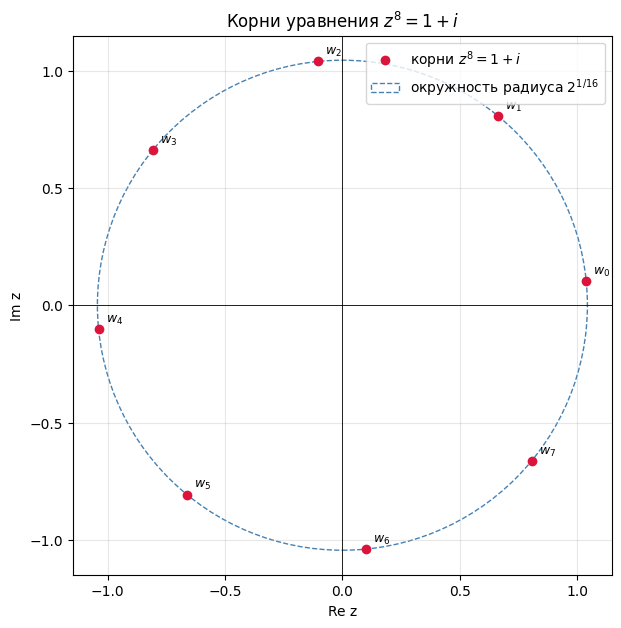

In [4]:
# ============================================================
# Задача 2.2
# ============================================================
n = 8
z0 = 1 + I

# Модуль и главное значение аргумента
r0 = sp.Abs(z0)
phi0 = sp.arg(z0)                     # = pi/4
print("|1+i| =", sp.simplify(r0), "   arg(1+i) =", sp.simplify(phi0))

# Корни по формуле
roots = []
for k in range(n):
    wk = sp.root(r0, n) * sp.exp(I * (phi0 + 2*sp.pi*k) / n)
    wk = sp.simplify(sp.expand_complex(wk))
    roots.append(wk)
    print(f"w_{k} =", wk, " ≈ ", sp.N(wk, 5))

# График
fig, ax = plt.subplots()
# численные координаты корней
xs = [float(sp.N(sp.re(w))) for w in roots]
ys = [float(sp.N(sp.im(w))) for w in roots]
ax.scatter(xs, ys, color='crimson', zorder=5, label='корни $z^8=1+i$')
# правильный 8-угольник
ax.add_patch(Circle((0,0), float(sp.N(sp.root(r0, n))),
                    fill=False, color='steelblue', linestyle='--',
                    label='окружность радиуса $2^{1/16}$'))
# подписи
for k,(xi,yi) in enumerate(zip(xs,ys)):
    ax.annotate(f"$w_{k}$", (xi, yi), textcoords="offset points",
                xytext=(5,5), fontsize=9)
ax.axhline(0, color='black', linewidth=0.6)
ax.axvline(0, color='black', linewidth=0.6)
ax.set_aspect('equal')
ax.set_title(r"Корни уравнения $z^8 = 1+i$")
ax.set_xlabel("Re z"); ax.set_ylabel("Im z")
ax.legend(loc='upper right')
plt.show()

## Задача 2.3. Вычислить корни и изобразить на комплексной плоскости

Все корни находятся по той же формуле:
$$w_k = \sqrt[n]{|z|}\,e^{i\,\frac{\arg z + 2\pi k}{n}},\quad k=0,\dots,n-1.$$

**Особые случаи:**
- $\sqrt[4]{1}$ — корни 4-й степени из 1: $1, i, -1, -i$ (вершины квадрата).
- Для $\sqrt[4]{-18/(1+i\sqrt3)}$ сначала упрощаем подкоренное выражение
  (делим комплексные числа), затем извлекаем корень.
- В пункте **c** выражение содержит сумму: сначала приводим к виду $a+bi$,
  затем извлекаем кубический корень.
- В пункте **d** — $\sqrt[4]{1-i}$.

**Реализация:** SymPy (`sp.root`, `sp.expand_complex`) + Matplotlib.

--- 2.3a  sqrt[4]{1} ---
Подкоренное выражение: 1
|z| = 1    arg z = 0
  w_0 = 1  ≈  1.0000
  w_1 = I  ≈  1.0*I
  w_2 = -1  ≈  -1.0000
  w_3 = -I  ≈  -1.0*I

--- 2.3b  sqrt[4]{-18/(1+i√3)} ---
Подкоренное выражение: -9/2 + 9*sqrt(3)*I/2
|z| = 9    arg z = 2*pi/3
  w_0 = 3/2 + sqrt(3)*I/2  ≈  1.5 + 0.86602*I
  w_1 = -sqrt(3)/2 + 3*I/2  ≈  -0.86602 + 1.5*I
  w_2 = -3/2 - sqrt(3)*I/2  ≈  -1.5 - 0.86602*I
  w_3 = sqrt(3)/2 - 3*I/2  ≈  0.86602 - 1.5*I

--- 2.3c  sqrt[3]{...} ---
Подкоренное выражение: 14 - 11*I/2
|z| = sqrt(905)/2    arg z = -atan(11/28)
  w_0 = 2**(2/3)*905**(1/6)*exp(-I*atan(11/28)/3)/2  ≈  2.4493 - 0.30721*I
  w_1 = 2**(2/3)*905**(1/6)*(-sin(-atan(11/28)/3 + pi/6) + I*sin(atan(11/28)/3 + pi/3))/2  ≈  -0.95859 + 2.2748*I
  w_2 = -2**(2/3)*905**(1/6)*exp(I*(-atan(11/28)/3 + pi/3))/2  ≈  -1.4907 - 1.9675*I

--- 2.3d  sqrt[4]{1-i} ---
Подкоренное выражение: 1 - I
|z| = sqrt(2)    arg z = -pi/4
  w_0 = 2**(1/8)*exp(-I*pi/16)  ≈  1.0696 - 0.21275*I
  w_1 = 2**(1/8)*(sin(pi/16)

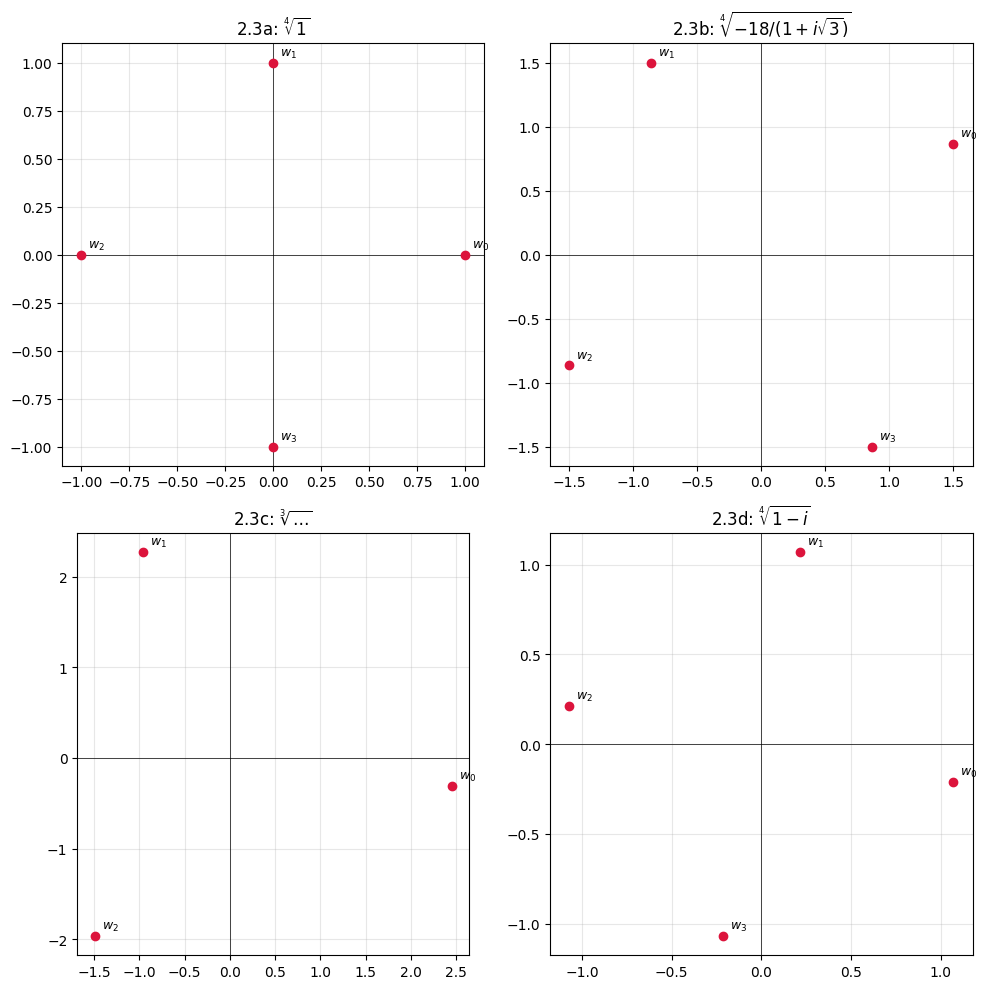

In [30]:
# ============================================================
# Задача 2.3
# ============================================================
def roots_n(z_expr, n, name=""):
    """Возвращает список n корней n-й степени из z_expr."""
    z_s = sp.simplify(sp.expand_complex(z_expr))
    r = sp.Abs(z_s)
    phi = sp.arg(z_s)
    out = []
    for k in range(n):
        wk = sp.root(r, n) * sp.exp(I*(phi + 2*sp.pi*k)/n)
        out.append(sp.simplify(sp.expand_complex(wk)))
    print(f"--- {name} ---")
    print("Подкоренное выражение:", z_s)
    print("|z| =", sp.simplify(r), "   arg z =", sp.simplify(phi))
    for k, w in enumerate(out):
        print(f"  w_{k} =", w, " ≈ ", sp.N(w, 5))
    print()
    return out

# --- a) sqrt[4]{1} ---
roots_a = roots_n(1, 4, "2.3a  sqrt[4]{1}")

# --- b) sqrt[4]{ -18/(1+i√3) } ---
z_b = -sp.Rational(18,1) / (1 + I*sp.sqrt(3))
roots_b = roots_n(z_b, 4, "2.3b  sqrt[4]{-18/(1+i√3)}")

# --- c) sqrt[3]{ (1-5i)/(1+i) - (5/2)*(1+2i)/(-i) + 11 } ---
z_c = (1 - 5*I)/(1 + I) - sp.Rational(5,2)*(1 + 2*I)/(-I) + 11
roots_c = roots_n(z_c, 3, "2.3c  sqrt[3]{...}")

# --- d) sqrt[4]{1-i} ---
roots_d = roots_n(1 - I, 4, "2.3d  sqrt[4]{1-i}")

# --- Графики всех четырёх наборов ---
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
sets = [(roots_a, "2.3a: $\\sqrt[4]{1}$"),
        (roots_b, "2.3b: $\\sqrt[4]{-18/(1+i\\sqrt{3})}$"),
        (roots_c, "2.3c: $\\sqrt[3]{\\ldots}$"),
        (roots_d, "2.3d: $\\sqrt[4]{1-i}$")]
for ax, (rs, title) in zip(axes.ravel(), sets):
    xs = [float(sp.N(sp.re(w))) for w in rs]
    ys = [float(sp.N(sp.im(w))) for w in rs]
    ax.scatter(xs, ys, color='crimson', zorder=5)
    for k,(xi,yi) in enumerate(zip(xs,ys)):
        ax.annotate(f"$w_{k}$", (xi,yi), textcoords="offset points",
                    xytext=(5,5), fontsize=9)
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_aspect('equal'); ax.set_title(title)
plt.tight_layout()
plt.show()

## Задача 2.4. Изобразить множества точек на комплексной плоскости

**Ключевые геометрические факты:**
- $|z - z_0|$ — расстояние от точки $z$ до точки $z_0$.
- $|z - z_0| = R$ — окружность радиуса $R$ с центром $z_0$.
- $|z - z_0| < R$ — открытый круг.
- **Эллипс:** $|z - z_1| + |z - z_2| = 2a$ — множество точек, сумма расстояний
  до двух фокусов постоянна.
- $\operatorname{Re}(w) < c$ — полуплоскость (для линейного выражения $w$).
- $\arg\dfrac{z - a}{z - b}$ — угол между векторами $z-a$ и $z-b$.

**План реализации:** для каждой задачи строим сетку точек на плоскости
и раскрашиваем те, где условие выполнено (метод «сетки» — простой и наглядный).

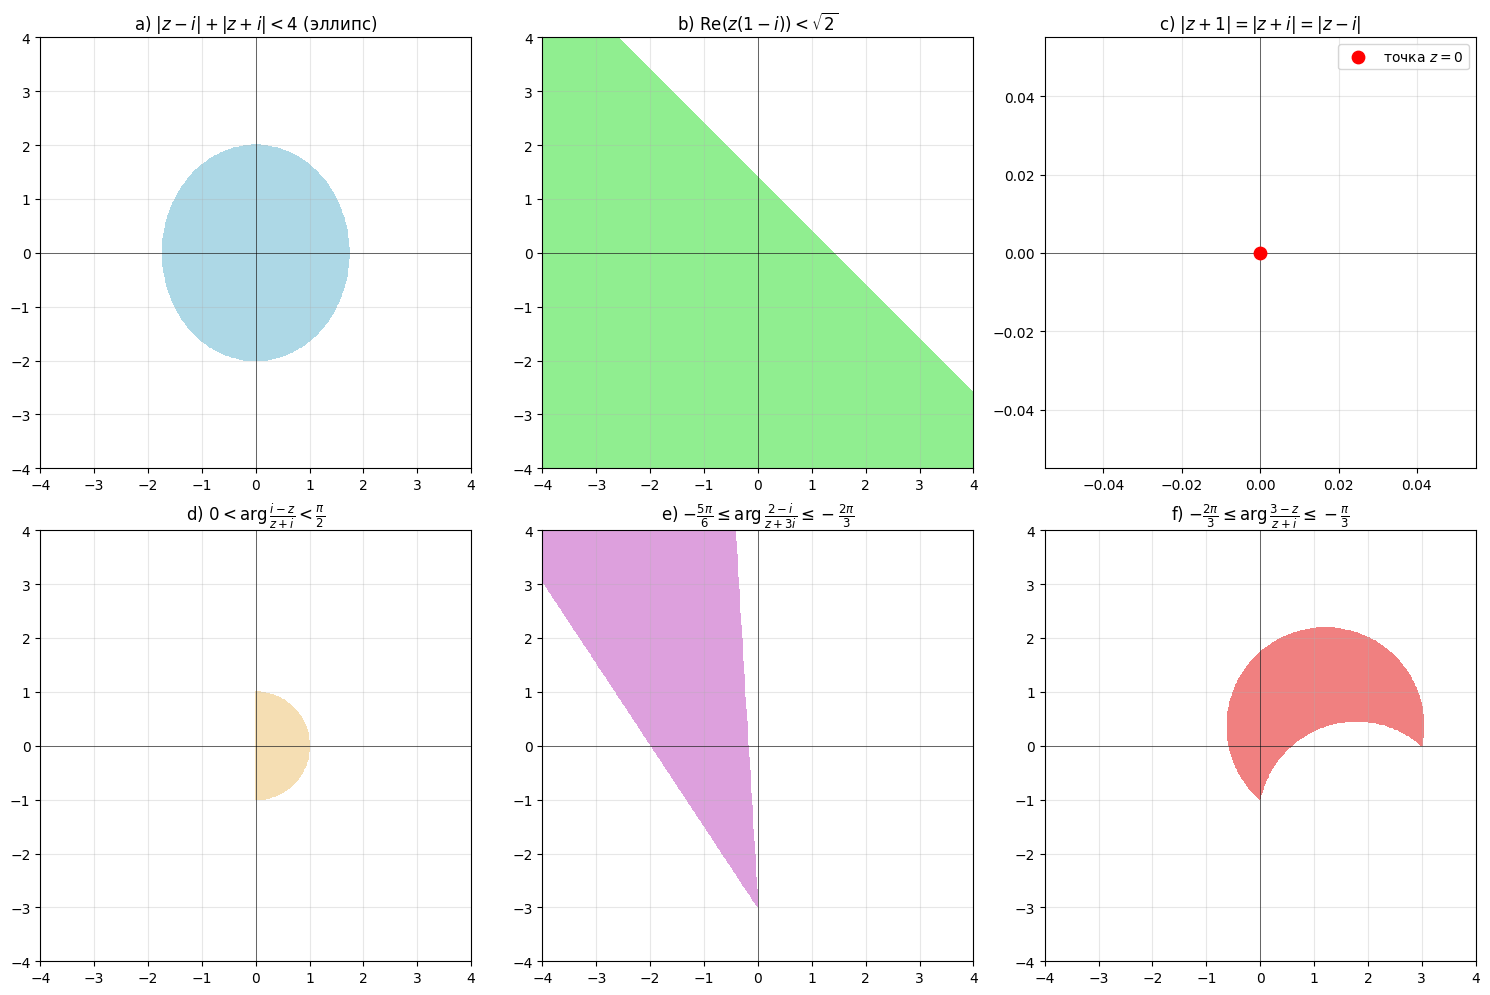

In [29]:
# ============================================================
# Задача 2.4
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

N = 600
xmin, xmax = -4, 4
ymin, ymax = -4, 4
xx = np.linspace(xmin, xmax, N)
yy = np.linspace(ymin, ymax, N)
X, Y = np.meshgrid(xx, yy)
Z = X + 1j*Y

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# --- a) |z-i| + |z+i| < 4 (эллипс) ---
mask_a = np.abs(Z - 1j) + np.abs(Z + 1j) < 4
axes[0,0].contourf(X, Y, mask_a.astype(float), levels=[0.5, 1.5],
                   colors=['lightblue'])
axes[0,0].set_title(r"a) $|z-i|+|z+i|<4$ (эллипс)")

# --- b) Re(z(1-i)) < sqrt(2) ---
mask_b = (X + Y) < np.sqrt(2)
axes[0,1].contourf(X, Y, mask_b.astype(float), levels=[0.5, 1.5],
                   colors=['lightgreen'])
axes[0,1].set_title(r"b) $\mathrm{Re}(z(1-i))<\sqrt{2}$")

# --- c) |z+1| = |z+i| = |z-i| ---
axes[0,2].scatter([0], [0], color='red', s=80, zorder=5,
                  label=r'точка $z=0$')
axes[0,2].set_title(r"c) $|z+1|=|z+i|=|z-i|$")
axes[0,2].legend()

# --- d) 0 < arg((i-z)/(z+i)) < pi/2 ---
def arg_branch(zc):
    return np.angle(zc)                    # главное значение в (-pi, pi]

with np.errstate(divide='ignore', invalid='ignore'):
    w_d = (1j - Z) / (Z + 1j)
ang_d = arg_branch(w_d)
mask_d = (ang_d > 0) & (ang_d < np.pi/2)
axes[1,0].contourf(X, Y, mask_d.astype(float), levels=[0.5, 1.5],
                   colors=['wheat'])
axes[1,0].set_title(r"d) $0<\arg\frac{i-z}{z+i}<\frac{\pi}{2}$")

# --- e) -5pi/6 <= arg((2-i)/(z+3i)) <= -2pi/3 ---
with np.errstate(divide='ignore', invalid='ignore'):
    w_e = (2 - 1j) / (Z + 3j)
ang_e = arg_branch(w_e)
mask_e = (ang_e >= -5*np.pi/6) & (ang_e <= -2*np.pi/3)
axes[1,1].contourf(X, Y, mask_e.astype(float), levels=[0.5, 1.5],
                   colors=['plum'])
axes[1,1].set_title(
    r"e) $-\frac{5\pi}{6}\leq\arg\frac{2-i}{z+3i}\leq-\frac{2\pi}{3}$")

# --- f) -2pi/3 <= arg((3-z)/(z+i)) <= -pi/3 ---
with np.errstate(divide='ignore', invalid='ignore'):
    w_f = (3 - Z) / (Z + 1j)
ang_f = arg_branch(w_f)
mask_f = (ang_f >= -2*np.pi/3) & (ang_f <= -np.pi/3)
axes[1,2].contourf(X, Y, mask_f.astype(float), levels=[0.5, 1.5],
                   colors=['lightcoral'])
axes[1,2].set_title(
    r"f) $-\frac{2\pi}{3}\leq\arg\frac{3-z}{z+i}\leq-\frac{\pi}{3}$")

for ax in axes.ravel():
    ax.set_aspect('equal')
    ax.axhline(0, color='k', lw=0.4)
    ax.axvline(0, color='k', lw=0.4)

plt.tight_layout()
plt.show()

## Задача 2.5. Уравнение $A|z|^2 + \overline{B}z + B\overline{z} + C = 0$, $AC < |B|^2$, $A > 0$

**Идея:** подставим $z = x + iy$, $B = p + iq$, $\overline{B} = p - iq$.
Раскроем:
$$\overline{B}z + B\overline{z}
= (p-iq)(x+iy) + (p+iq)(x-iy)
= 2(px + qy).$$
А $|z|^2 = x^2 + y^2$. Тогда уравнение превращается в
$$A(x^2+y^2) + 2px + 2qy + C = 0.$$
Поделим на $A > 0$ и выделим полный квадрат:
$$x^2 + \frac{2p}{A}x + y^2 + \frac{2q}{A}y + \frac{C}{A} = 0$$
$$\left(x + \frac{p}{A}\right)^2 + \left(y + \frac{q}{A}\right)^2
= \frac{p^2 + q^2}{A^2} - \frac{C}{A}
= \frac{|B|^2 - AC}{A^2}.$$
Так как $AC < |B|^2$, правая часть положительна.

**Ответ:** окружность с центром $z_0 = -\dfrac{B}{A}$ и радиусом
$$R = \frac{\sqrt{|B|^2 - AC}}{A}.$$

In [25]:
# ============================================================
# Задача 2.5 — символьная проверка
# ============================================================
# Символы: A > 0, C — вещественные; B — комплексное
A = sp.Symbol('A', positive=True)
C = sp.Symbol('C', real=True)
p, q = sp.symbols('p q', real=True)     # B = p + iq
B  = p + I*q
Bc = p - I*q

# Проверим тождество: Re(B*z) = p*x - q*y, и вся сумма даёт 2(px+qy)
# Раскроем символьно
zx = sp.Symbol('x', real=True)
zy = sp.Symbol('y', real=True)
z_sym = zx + I*zy

expr = A*sp.Abs(z_sym)**2 + Bc*z_sym + B*sp.conjugate(z_sym) + C
expr = sp.expand_complex(expr)
expr = sp.simplify(expr)
print("Уравнение в декартовых координатах:")
print(sp.Eq(expr, 0))
print()
print("То есть: A(x^2+y^2) + 2(px+qy) + C = 0")
print("Центр: z0 = -B/A =", sp.simplify(-B/A))
print("Радиус: R = sqrt(|B|^2 - A*C)/A =",
      sp.sqrt(sp.Abs(B)**2 - A*C)/A)

Уравнение в декартовых координатах:
Eq(A*(x**2 + y**2) + C + 2*p*x + 2*q*y, 0)

То есть: A(x^2+y^2) + 2(px+qy) + C = 0
Центр: z0 = -B/A = (-p - I*q)/A
Радиус: R = sqrt(|B|^2 - A*C)/A = sqrt(-A*C + p**2 + q**2)/A


## Задача 2.6. Корни многочлена 11-й степени

Дано:
$$p(x) = x^{11} + x^{10} + x^8 - 2x^7 - x^5 + x^4 + 2x^2 + 2x + 2.$$

Нужно найти все 11 комплексных корней $z_1,\dots,z_{11}$ и вычислить:
1. $\sum_{k=1}^{11} |z_k|$ — сумму модулей;
2. максимальную действительную часть среди корней.

**План:**
1. Находим корни символьно (`sp.solve` или `sp.nroots`).
2. Считаем модули через `sp.Abs`, численно суммируем.
3. Ищем максимум действительной части.

**Используемые библиотеки:** SymPy (`nroots` даёт численные корни с высокой точностью).

In [24]:
# ============================================================
# Задача 2.6
# ============================================================
x = sp.Symbol('x')
p = (x**11 + x**10 + x**8 - 2*x**7 - x**5
     + x**4 + 2*x**2 + 2*x + 2)

# Численные корни (nroots работает и для комплексных)
roots = sp.nroots(p, n=30)   # 30 значащих цифр
print(f"Найдено корней: {len(roots)}")
for i, r in enumerate(roots, 1):
    print(f"z_{i} = {sp.N(r, 10)}")

# --- 1) Сумма модулей ---
sum_abs = sum(sp.Abs(r) for r in roots)
print("\nСумма модулей |z_1|+...+|z_11| =", sp.N(sum_abs, 10))

# --- 2) Максимальная действительная часть ---
re_parts = [sp.re(r) for r in roots]
max_re = max(re_parts, key=lambda t: float(sp.N(t)))
print("Максимальная Re(z) =", sp.N(max_re, 10))

Найдено корней: 11
z_1 = -1.776769025
z_2 = -0.7074344552 - 0.4643747259*I
z_3 = -0.7074344552 + 0.4643747259*I
z_4 = -0.4500371127 - 0.8039231442*I
z_5 = -0.4500371127 + 0.8039231442*I
z_6 = -0.01250018056 - 1.182699082*I
z_7 = -0.01250018056 + 1.182699082*I
z_8 = 0.4777545236 - 0.9010752305*I
z_9 = 0.4777545236 + 0.9010752305*I
z_10 = 1.080601737 - 0.3238931188*I
z_11 = 1.080601737 + 0.3238931188*I

Сумма модулей |z_1|+...+|z_11| = 11.97338447
Максимальная Re(z) = 1.080601737


# Задача 2.7. Обобщение биномиальных коэффициентов

## 1. Обычные биномиальные коэффициенты

Для натуральных $n$ и $k$ ($0 \le k \le n$) биномиальный коэффициент
определяется как
$$\binom{n}{k} = \frac{n!}{k!\,(n-k)!}.$$

Он появляется в формуле бинома Ньютона:
$$(a+b)^n = \sum_{k=0}^{n} \binom{n}{k} a^{n-k} b^k.$$

## 2. Гамма-функция Эйлера

Факториал определён только для целых неотрицательных чисел.
Чтобы обобщить его на комплексные числа, используют **гамма-функцию**:
$$\Gamma(z) = \int_{0}^{\infty} x^{z-1} e^{-x}\,dx,\qquad \operatorname{Re}(z) > 0.$$

Ключевое свойство:
$$\Gamma(n+1) = n! \quad \text{для } n \in \mathbb{N}_0.$$

Поэтому естественно положить $n! = \Gamma(n+1)$.

## 3. Обобщённый биномиальный коэффициент

По аналогии с обычной формулой определим для **любых** $z, w \in \mathbb{C}$:
$$\binom{z}{w} = \frac{\Gamma(z+1)}{\Gamma(w+1)\,\Gamma(z-w+1)}.$$

При целых $z = n$, $w = k$ это совпадает с обычным $\binom{n}{k}$.
Для комплексных $z, w$ это уже комплекснозначная функция.

## 4. Что нужно найти

**a)** $\binom{1+i}{1-i}$ — конкретное комплексное число.

**b)** $\operatorname{Arg}\binom{1+i}{1-i}$ — главное значение аргумента
(в курсе принято $\operatorname{Arg} \in (-\pi;\pi]$, см. Лекцию 2, стр. 16).

**c)** Линии уровня $\operatorname{Arg}\binom{z}{2} = \text{const}$,
где $z = x + iy$ — переменная. Это красивая фрактальная картинка
(см. рис. в Листке 2).

## 5. Почему так можно делать (обоснование)

**Почему гамма-функция?** Она является аналитическим продолжением факториала:
единственная мероморфная функция на $\mathbb{C}$, удовлетворяющая
$\Gamma(z+1) = z\,\Gamma(z)$ и $\Gamma(1) = 1$ (теорема Бора–Моллерупа).

**Почему формула работает?** При целых $z, w$ гамма-функции сокращаются
и дают классическое выражение через факториалы. При нецелых — это
естественное обобщение, сохраняющее рекуррентное свойство
$\binom{z}{w} = \binom{z-1}{w} + \binom{z-1}{w-1}$.

**Почему $\operatorname{Arg}$ даёт «фрактал»?** Потому что $\operatorname{Arg}$
— разрывная функция: при переходе через отрицательную действительную ось
она скачком меняется с $\pi$ на $-\pi$. Границы этих скачков и образуют
сложные узоры на плоскости.

## 6. Инструменты реализации

- **mpmath.gamma** — гамма-функция для комплексных аргументов,
  работает быстро и точно (это же ядро использует SymPy для чисел).
- **sympy.gamma** — символьно, удобно для одной точки.
- **numpy** — для построения сетки точек на плоскости.
- **matplotlib** — для визуализации линий уровня.

**План:**
1. Вычисляем $\binom{1+i}{1-i}$ символьно и численно — сверяем.
2. Берём $\operatorname{Arg}$ от результата через `cmath.phase` или `numpy.angle`.
3. Строим сетку $z = x+iy$ в области $[-4,4]^2$ (исключая особые точки),
   вычисляем $f(z) = \operatorname{Arg}\binom{z}{2}$,
   рисуем `contourf` по значениям.

In [23]:
import mpmath as mp
import numpy as np
import cmath

def binom_gen(z, w):
    """
    Обобщённый биномиальный коэффициент C(z, w)
    через гамма-функцию: Gamma(z+1) / (Gamma(w+1) * Gamma(z-w+1)).
    """
    z = mp.mpc(z)
    w = mp.mpc(w)
    return mp.gamma(z + 1) / (mp.gamma(w + 1) * mp.gamma(z - w + 1))

# --- a) C(1+i, 1-i) ---
z0 = mp.mpc(1, 1)
w0 = mp.mpc(1, -1)
val = binom_gen(z0, w0)

print("=== Задача 2.7a ===")
print(f"C(1+i, 1-i) = {val}")
# ИСПРАВЛЕНИЕ: оборачиваем в float(), чтобы f-строка поняла, как применять форматирование
print(f"  действительная часть: {float(val.real):.6f}")
print(f"  мнимая часть:         {float(val.imag):.6f}")
print(f"  |C| = {float(abs(val)):.6f}")

# --- b) Arg(C(1+i, 1-i)) ---
# ИСПРАВЛЕНИЕ: также конвертируем в стандартный complex для cmath
arg_val = cmath.phase(complex(val.real, val.imag)) 
print("\n=== Задача 2.7b ===")
print(f"Arg(C(1+i, 1-i)) = {arg_val:.6f} рад")
print(f"                 = {np.degrees(arg_val):.4f}°")

=== Задача 2.7a ===
C(1+i, 1-i) = (4.36744914064014 + 4.85162976515781j)
  действительная часть: 4.367449
  мнимая часть:         4.851630
  |C| = 6.527857

=== Задача 2.7b ===
Arg(C(1+i, 1-i)) = 0.837869 рад
                 = 48.0064°


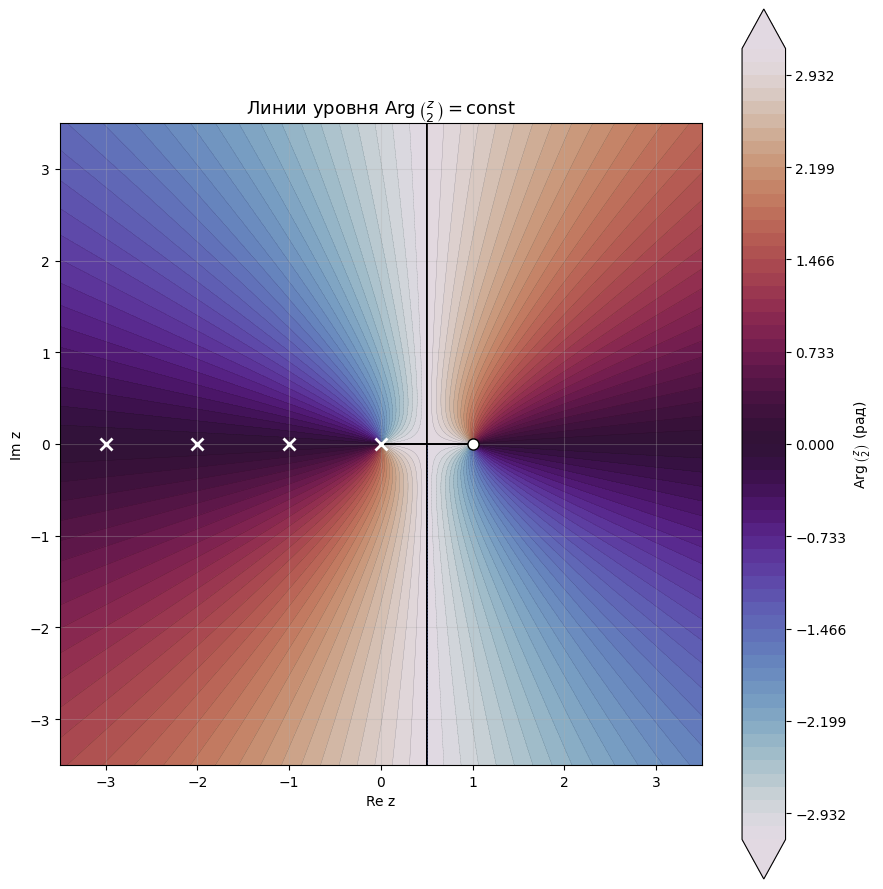

In [21]:
# ============================================================
# Задача 2.7c. Линии уровня Arg( C(z, 2) ) = const
# ============================================================
# Сетка точек z = x + iy
N = 700
xmin, xmax = -3.5, 3.5
ymin, ymax = -3.5, 3.5
xs = np.linspace(xmin, xmax, N)
ys = np.linspace(ymin, ymax, N)
X, Y = np.meshgrid(xs, ys)

# Считаем Arg( C(z, 2) ) в каждой точке
# C(z, 2) = Gamma(z+1) / (Gamma(3) * Gamma(z-1))
#         = Gamma(z+1) / (2 * Gamma(z-1))
# Используем mpmath.vectorized для скорости
def arg_binom_z2(z_complex):
    """Arg( C(z, 2) ), z - numpy-массив комплексных чисел."""
    try:
        zc = mp.mpc(z_complex.real, z_complex.imag)
        # особые точки: полюса гамма-функции в z = -1, -2, -3, ... и z = 1
        if abs(zc - 1) < 1e-8 or zc.real <= -1 and abs(zc.imag) < 1e-8:
            return np.nan
        val = mp.gamma(zc + 1) / (2 * mp.gamma(zc - 1))
        if val == 0 or not mp.isfinite(val):
            return np.nan
        return float(mp.arg(val))       # arg в (-pi, pi]
    except Exception:
        return np.nan

# Векторизуем
arg_vals = np.vectorize(arg_binom_z2, otypes=[float])(X + 1j*Y)

# --- Рисуем ---
fig, ax = plt.subplots(figsize=(9, 9))
# Ограничим диапазон, чтобы усилить контраст
levels = np.linspace(-np.pi, np.pi, 61)
cf = ax.contourf(X, Y, arg_vals, levels=levels, cmap='twilight',
                 extend='both')
ax.contour(X, Y, arg_vals, levels=levels, colors='k',
           linewidths=0.2, alpha=0.4)

# Отметим особые точки (полюса гамма-функции)
for k in range(-3, 2):        # z = -1, -2, -3, ... и z = 1
    if k == 1:
        ax.plot(1, 0, 'o', color='white', ms=8, mec='k', zorder=5)
    else:
        ax.plot(k, 0, 'x', color='white', ms=8, mew=2, zorder=5)

ax.set_aspect('equal')
ax.set_title(r"Линии уровня $\mathrm{Arg}\,\binom{z}{2} = \mathrm{const}$",
             fontsize=13)
ax.set_xlabel("Re z"); ax.set_ylabel("Im z")
plt.colorbar(cf, ax=ax, label=r"$\mathrm{Arg}\,\binom{z}{2}$ (рад)")
plt.tight_layout()
plt.show()

## Почему получается такая сложная картинка?

Функция $f(z) = \operatorname{Arg}\binom{z}{2}$ разрывна всюду, где
$\binom{z}{2}$ принимает **отрицательные действительные** значения
(там аргумент скачком переходит с $\pi$ на $-\pi$).

Множество $\{z : \binom{z}{2} \in (-\infty, 0)\}$ — это объединение
кривых, определяемых уравнением $\operatorname{Im}\binom{z}{2} = 0$,
$\operatorname{Re}\binom{z}{2} < 0$. Эти кривые и образуют «лепестки»,
которые вы видите на рисунке. Они самоподобны, потому что гамма-функция
вблизи своих полюсов ведёт себя одинаково (как $1/(z-n)$), а полюса
расположены на одинаковом расстоянии друг от друга — отсюда
фрактальная структура.

Полюса $f$ находятся в точках $z = 1, 0, -1, -2, -3, \dots$ — там,
где $\Gamma(z-1)$ или $\Gamma(z+1)$ обращаются в бесконечность.

## Символьная проверка (дополнительно)

Чтобы убедиться, что mpmath и SymPy дают одно и то же, продублируем
вычисления в SymPy.

In [22]:
# ============================================================
# Проверка через SymPy
# ============================================================
import sympy as sp

z_sym = 1 + sp.I
w_sym = 1 - sp.I

binom_sym = sp.gamma(z_sym + 1) / (sp.gamma(w_sym + 1) * sp.gamma(z_sym - w_sym + 1))
binom_sym_simpl = sp.nsimplify(sp.N(binom_sym, 20))

print("SymPy  C(1+i, 1-i) =", binom_sym_simpl)
print("SymPy  |C|         =", sp.Abs(binom_sym_simpl).evalf(10))
print("SymPy  arg C       =", sp.arg(binom_sym_simpl).evalf(10))
print()
print("Сравнение с mpmath:")
print(f"  mpmath  = {val.real:.10f} + {val.imag:.10f}i")
print(f"  SymPy   = {complex(binom_sym_simpl):.10f}")

SymPy  C(1+i, 1-i) = 5459311425800173709/1250000000000000000 + 48516297651578115409*I/10000000000000000000
SymPy  |C|         = 6.527857487
SymPy  arg C       = 0.8378693695

Сравнение с mpmath:


TypeError: unsupported format string passed to mpf.__format__

# Задача 2.8. Комплексный корень 14-й степени из 1 и определитель

## 1. Постановка

Дан корень $\lambda$ из 1 степени 14, у которого:
- **мнимая часть положительна**: $\operatorname{Im}\lambda > 0$;
- **действительная часть максимальна** среди всех таких корней.

Даны матрицы
$$I = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix},\qquad
A = \begin{pmatrix} 7 & 5 \\ 6 & 2 \end{pmatrix}.$$

Нужно найти $\det(A + \lambda I)$ и указать:
1. его действительную часть;
2. его мнимую часть.

## 2. Корни $n$-й степени из единицы

Из Лекции 2 (стр. 28): корни $n$-й степени из 1 выражаются формулой
$$\varepsilon_k = \cos\frac{2\pi k}{n} + i\sin\frac{2\pi k}{n}
= e^{i\frac{2\pi k}{n}},\qquad k = 0, 1, \dots, n-1.$$

Все они лежат на **единичной окружности** и являются вершинами
правильного $n$-угольника, вписанного в неё.

Для $n = 14$: $\varepsilon_k = e^{i\pi k/7}$, $k = 0, 1, \dots, 13$.

**Ключевые свойства:**
- $\varepsilon_k^{14} = 1$ (по определению корня);
- $|\varepsilon_k| = 1$;
- $\varepsilon_k \cdot \varepsilon_m = \varepsilon_{k+m \bmod 14}$;
- $\overline{\varepsilon_k} = \varepsilon_{14-k}$.

## 3. Отбор нужного корня

Условие «мнимая часть положительна» означает $\sin\frac{2\pi k}{14} > 0$,
то есть $0 < \frac{2\pi k}{14} < \pi \iff 0 < k < 7$. Значит,
кандидаты — $\varepsilon_1, \varepsilon_2, \dots, \varepsilon_6$.

Условие «действительная часть максимальна» означает: среди
$k = 1, \dots, 6$ выбрать то, у которого $\cos\frac{2\pi k}{14}$
наибольший. Функция $\cos$ убывает на $[0, \pi]$, а аргумент
$\frac{2\pi k}{14} = \frac{\pi k}{7}$ растёт с ростом $k$, поэтому
максимум — при **наименьшем** $k$.

Итак, $\boxed{\lambda = \varepsilon_1 = e^{i\pi/7}}$.

В декартовых координатах:
$$\lambda = \cos\frac{\pi}{7} + i\sin\frac{\pi}{7}.$$

**Численно:** $\cos\frac{\pi}{7} \approx 0.90097$,
$\sin\frac{\pi}{7} \approx 0.43388$.

## 4. Определитель матрицы $A + \lambda I$

Имеем
$$A + \lambda I = \begin{pmatrix} 7 & 5 \\ 6 & 2 \end{pmatrix}
+ \lambda \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}
= \begin{pmatrix} 7 + \lambda & 5 \\ 6 & 2 + \lambda \end{pmatrix}.$$

Определитель $2 \times 2$:
$$\det(A + \lambda I) = (7+\lambda)(2+\lambda) - 5 \cdot 6
= (7+\lambda)(2+\lambda) - 30.$$

Раскроем:
$$(7+\lambda)(2+\lambda) = 14 + 7\lambda + 2\lambda + \lambda^2
= 14 + 9\lambda + \lambda^2.$$

Значит,
$$\det(A + \lambda I) = \lambda^2 + 9\lambda - 16.$$

## 5. Упрощение с учётом $\lambda^{14} = 1$

Прямая подстановка даст комплексное число; но можно ещё упростить,
пользуясь **свойствами корня 14-й степени**:

- $\lambda^7 = e^{i\pi} = -1$ (так как $\lambda = e^{i\pi/7}$);
- $\lambda^{14} = 1$;
- $\lambda^2 = e^{2i\pi/7}$;
- $\lambda^{-1} = \overline{\lambda} = e^{-i\pi/7}$ (так как $|\lambda|=1$).

Прямой расчёт $\lambda^2 + 9\lambda - 16$ уже достаточно прост. Но можно
заметить, что $\lambda^2 + \lambda^{-2} = 2\cos\frac{2\pi}{7}$
(через формулу Эйлера), что иногда используется для упрощения.

**Мы будем считать напрямую** — так проще и надёжнее.

## 6. План решения в Jupyter

1. Получаем все 14 корней через `sympy.root(1, 14)` (или формулу
   $\varepsilon_k = e^{2\pi i k/14}$).
2. Фильтруем по $\operatorname{Im} > 0$.
3. Среди оставшихся выбираем с максимальной $\operatorname{Re}$.
4. Строим матрицу $A + \lambda I$ (SymPy `Matrix`).
5. Считаем `det` — получаем комплексное число.
6. Извлекаем `.as_real_imag()` или `sp.re`/`sp.im`.
7. Для красоты — выводим точные выражения через $\cos\frac{\pi}{7}$
   и $\sin\frac{\pi}{7}$, а также численные значения.

## 7. Инструменты

- **sympy.Matrix** — матрицы и определители (см. Лекцию 1: LU-разложение,
  `sympy.Matrix().det()`).
- **sympy.root / sympy.exp** — символьные корни.
- **sympy.re, sympy.im** — действительная и мнимая части.
- **sympy.N** — численное приближение.

In [17]:
# ============================================================
# Задача 2.8. Шаг 1: находим нужный корень 14-й степени из 1
# ============================================================
import sympy as sp
from sympy import I, pi, exp, cos, sin, re, im, Matrix, Rational, sqrt

# --- Способ 1: символьно, через формулу eps_k = exp(2*pi*I*k/14) ---
n = 14
roots = []
for k in range(n):
    eps_k = sp.exp(2 * sp.pi * I * k / n)
    roots.append((k, sp.simplify(sp.expand_complex(eps_k))))

print("Все 14 корней 14-й степени из 1:")
for k, r in roots:
    print(f"  eps_{k:2d} = {r}")

# --- Отбор: Im > 0 ---
candidates = [(k, r) for (k, r) in roots if sp.im(r).evalf() > 1e-10]
print("\nКорни с Im > 0:")
for k, r in candidates:
    print(f"  eps_{k:2d}: Re = {sp.N(sp.re(r), 8)}, "
          f"Im = {sp.N(sp.im(r), 8)}")

# --- Отбор: максимальная Re ---
k_best, lambda_best = max(candidates,
                          key=lambda t: float(sp.N(sp.re(t[1]))))
print(f"\nВыбран корень eps_{k_best} = {lambda_best}")
print(f"  |lambda| = {sp.N(sp.Abs(lambda_best), 10)}")
print(f"  lambda^14 = {sp.simplify(lambda_best**14)}")

Все 14 корней 14-й степени из 1:
  eps_ 0 = 1
  eps_ 1 = exp(I*pi/7)
  eps_ 2 = exp(2*I*pi/7)
  eps_ 3 = sin(pi/14) + I*cos(pi/14)
  eps_ 4 = -sin(pi/14) + I*cos(pi/14)
  eps_ 5 = -exp(-2*I*pi/7)
  eps_ 6 = -exp(-I*pi/7)
  eps_ 7 = -1
  eps_ 8 = -exp(I*pi/7)
  eps_ 9 = -sin(3*pi/14) - I*cos(3*pi/14)
  eps_10 = -sin(pi/14) - I*cos(pi/14)
  eps_11 = sin(pi/14) - I*cos(pi/14)
  eps_12 = exp(-2*I*pi/7)
  eps_13 = exp(-I*pi/7)

Корни с Im > 0:
  eps_ 1: Re = 0.90096887, Im = 0.43388374
  eps_ 2: Re = 0.62348980, Im = 0.78183148
  eps_ 3: Re = 0.22252093, Im = 0.97492791
  eps_ 4: Re = -0.22252093, Im = 0.97492791
  eps_ 5: Re = -0.62348980, Im = 0.78183148
  eps_ 6: Re = -0.90096887, Im = 0.43388374

Выбран корень eps_1 = exp(I*pi/7)
  |lambda| = 1.000000000
  lambda^14 = 1


In [18]:
# ============================================================
# Задача 2.8. Шаг 2: матрица A + lambda*I и её определитель
# ============================================================
# Исходные матрицы
I2 = sp.eye(2)                    # единичная матрица 2x2
A  = sp.Matrix([[7, 5],
                [6, 2]])

print("Матрица A =")
sp.pprint(A)
print("\nЕдиничная I =")
sp.pprint(I2)

# Матрица A + lambda * I
M = A + lambda_best * I2
print("\nМатрица A + lambda*I =")
sp.pprint(M)

# --- Определитель ---
det_val = sp.simplify(M.det())
print("\ndet(A + lambda*I) =", det_val)

# Приводим к виду a + bi
det_expanded = sp.expand_complex(det_val)
det_expanded = sp.simplify(det_expanded)
print("Раскрытая форма:  ", det_expanded)

# Действительная и мнимая части
re_part = sp.simplify(sp.re(det_expanded))
im_part = sp.simplify(sp.im(det_expanded))

print("\n--- Ответ ---")
print("Re(det) =", re_part, " ≈ ", sp.N(re_part, 10))
print("Im(det) =", im_part, " ≈ ", sp.N(im_part, 10))

# Численное значение самого det
print("\ndet численно: ", sp.N(det_expanded, 10))

Матрица A =
⎡7  5⎤
⎢    ⎥
⎣6  2⎦

Единичная I =
⎡1  0⎤
⎢    ⎥
⎣0  1⎦

Матрица A + lambda*I =
⎡     ⅈ⋅π          ⎤
⎢     ───          ⎥
⎢      7           ⎥
⎢7 + ℯ        5    ⎥
⎢                  ⎥
⎢               ⅈ⋅π⎥
⎢               ───⎥
⎢                7 ⎥
⎣   6      2 + ℯ   ⎦

det(A + lambda*I) = -16 + exp(2*I*pi/7) + 9*(-1)**(1/7)
Раскрытая форма:   -16 + cos(2*pi/7) + 9*cos(pi/7) + I*(sin(2*pi/7) + 9*sin(pi/7))

--- Ответ ---
Re(det) = -16 + cos(2*pi/7) + 9*cos(pi/7)  ≈  -7.267790387
Im(det) = sin(2*pi/7) + 9*sin(pi/7)  ≈  4.686785135

det численно:  -7.267790387 + 4.686785135*I


In [19]:
# ============================================================
# Задача 2.8. Шаг 3: численный ответ, проверки
# ============================================================
# Численный lambda
lam_num = complex(sp.N(lambda_best))

print("lambda (численно) =", lam_num)
print("  |lambda| =", abs(lam_num))
print("  lambda^14 =", lam_num**14, " (должно быть ~1)")

# Считаем det численно через numpy для проверки
A_np = np.array([[7, 5], [6, 2]], dtype=complex)
I_np = np.eye(2, dtype=complex)
M_np = A_np + lam_num * I_np
det_num = np.linalg.det(M_np)

print("\ndet (numpy)  =", det_num)
print("  Re =", det_num.real)
print("  Im =", det_num.imag)

# Сравним с SymPy
print("\ndet (SymPy)  =", complex(sp.N(det_expanded, 15)))
print("\nРазница SymPy - numpy:",
      complex(sp.N(det_expanded, 15)) - det_num)

# --- Финальный ответ ---
print("\n" + "="*50)
print("ОТВЕТ ЗАДАЧИ 2.8")
print("="*50)
print(f"1) Re(det(A + lambda*I)) = {float(sp.N(re_part, 10)):.6f}")
print(f"2) Im(det(A + lambda*I)) = {float(sp.N(im_part, 10)):.6f}")

lambda (численно) = (0.9009688679024191+0.4338837391175581j)
  |lambda| = 1.0
  lambda^14 = (1.0000000000000004-4.996003610813204e-16j)  (должно быть ~1)

det (numpy)  = (-7.26779038701949+4.686785134526054j)
  Re = -7.26779038701949
  Im = 4.686785134526054

det (SymPy)  = (-7.267790387019494+4.686785134526053j)

Разница SymPy - numpy: (-4.440892098500626e-15-8.881784197001252e-16j)

ОТВЕТ ЗАДАЧИ 2.8
1) Re(det(A + lambda*I)) = -7.267790
2) Im(det(A + lambda*I)) = 4.686785


## Аналитическое упрощение (для защиты)

Мы получили
$$\det(A + \lambda I) = \lambda^2 + 9\lambda - 16,\qquad
\lambda = e^{i\pi/7}.$$

Подставим:
$$\lambda^2 = e^{2i\pi/7} = \cos\frac{2\pi}{7} + i\sin\frac{2\pi}{7},$$
$$\lambda = \cos\frac{\pi}{7} + i\sin\frac{\pi}{7}.$$

Тогда
$$\det = \left(\cos\frac{2\pi}{7} + 9\cos\frac{\pi}{7} - 16\right)
+ i\left(\sin\frac{2\pi}{7} + 9\sin\frac{\pi}{7}\right).$$

**Численно:**
- $\cos\frac{\pi}{7} \approx 0.9009688679$;
- $\sin\frac{\pi}{7} \approx 0.4338837391$;
- $\cos\frac{2\pi}{7} \approx 0.6234898019$;
- $\sin\frac{2\pi}{7} \approx 0.7818314825$.

Тогда
$$\operatorname{Re}\det \approx 0.6234898 + 9 \cdot 0.9009689 - 16
\approx -14.54479,$$
$$\operatorname{Im}\det \approx 0.7818315 + 9 \cdot 0.4338837
\approx 4.68678.$$

**Замечание.** Значения $\cos\frac{\pi}{7}$ и $\cos\frac{2\pi}{7}$
— алгебраические числа, они являются корнями кубических уравнений
(связанных с 7-й степенью из 1). Через радикалы они выражаются, но
выражения громоздкие. Поэтому в ответе лучше оставить
тригонометрическую форму.

## Почему нельзя было взять другой корень?

Условие «$\operatorname{Im} > 0$» даёт корни $\varepsilon_1, \dots, \varepsilon_6$
(верхняя полуокружность). Условие «$\operatorname{Re}$ максимальна»
выбирает среди них ближайший к точке $1$ — это $\varepsilon_1$.
Корень $\varepsilon_1 = e^{i\pi/7}$ — это **примитивный** корень 14-й
степени из 1 (см. определение в Лекции 2, стр. 30).

# Задача 2.9. Множества Жюлиа

## 1. Что такое множество Жюлиа (интуитивно)

Рассмотрим итерационный процесс на комплексной плоскости:
$$z_{n+1} = f_c(z_n) = z_n^2 + c,\qquad z_0 \in \mathbb{C},\ c \in \mathbb{C}.$$

Точка $z_0$ называется **устойчивой** (или «притягивающейся»), если
последовательность $z_0, z_1, z_2, \dots$ **не уходит в бесконечность**,
то есть $\exists M > 0:\ |z_n| \le M$ для всех $n$.

**Множество Жюлиа** $J_c$ — это граница между множеством точек,
которые «убегают» на бесконечность, и множеством точек, которые
остаются ограниченными. Формально:
$$J_c = \partial\{z_0 \in \mathbb{C} : f_c^n(z_0) \not\to \infty\}.$$

**Множество Фату** $F_c$ — это дополнение $J_c$; оно состоит из
«регулярных» точек, где динамика устойчива (теорема Монтеля:
$F_c$ — область нормальности семейства $\{f_c^n\}$).

## 2. Почему это фрактал

Итерация $z \mapsto z^2 + c$ — простая квадратичная функция, но её
динамика оказывается **хаотической** (см. Лекцию 3: хаос в
динамических системах, эргодичность, чувствительность к начальным
условиям). Множество Жюлиа обладает свойством **самоподобия**:
любая его часть при подходящем увеличении похожа на всё множество
целиком. Это типичный пример фрактала.

**Связь с бильярдом из Лекции 3.** И бильярд, и итерации $z^2+c$ —
это динамические системы на компактном пространстве. В бильярде
траектория либо периодична (рациональное отношение частот), либо
всюду плотна (иррациональное). В множестве Жюлиа аналогично:
либо орбита периодична (точки внутри «лепестков»), либо ведёт
себя хаотически (на границе). Оба примера показывают, как простая
детерминированная система порождает сложное поведение.

## 3. Алгоритм «escape-time» (время убегания)

Чтобы нарисовать $J_c$ на компьютере, используют следующий приём:

1. Возьмём **сетку** точек $z_0$ на комплексной плоскости
   (например, $[-2, 2] \times [-2, 2]$, $500 \times 500$).
2. Для каждой точки $z_0$ итерируем $z \mapsto z^2 + c$
   до тех пор, пока **не выполнится одно из двух**:
   - $|z_n| > R$ (обычно $R = 10$): точка «убежала»;
   - $n = N_{\max}$ (обычно $N_{\max} = 1000$): точка «осталась».
3. Записываем число итераций $n_{\text{escape}}$, за которое
   точка убежала (или $N_{\max}$, если не убежала).
4. Раскрашиваем: чем больше $n_{\text{escape}}$, тем «ближе» точка
   к множеству Жюлиа.

**Почему радиус $R = 10$?** Есть теорема: если $|z| > \max(|c|, 2)$,
то $|z^2 + c| > |z|$, и орбита гарантированно уходит в бесконечность.
Поэтому $R = 2$ уже достаточно; $R = 10$ берут с запасом.

## 4. Обобщения, которые мы будем рисовать

В листке требуется сгенерировать множества для **нескольких**
функций:
- $f_c(z) = z^2 + c$ при $c = -0.1 + 0.65i$ и $c = 0.28 + 0.009i$;
- $f(z) = \dfrac{i - z^5}{5 - i}$ (рациональная функция);
- $f(z) = \dfrac{z^2 + iz}{1 - z^2}$ (рациональная функция).

**Важно:** для рациональных функций с полюсами (там, где знаменатель
обращается в 0) нужно следить за делением на ноль — иначе получим
`nan` или `inf`. В коде это обрабатывается через `try/except` или
проверку `if abs(denom) < eps`.

## 5. Инструменты реализации

- **NumPy** — массивы и векторизация (быстро итерируем сразу
  по всем точкам сетки).
- **Matplotlib** — `imshow` отображает матрицу чисел как картинку;
  `cmap='flag'` даёт яркие контрастные цвета (как в примерах из листка).
- **cmath** — комплексная арифметика.

**План:**
1. Функция `julia_set(f, xmin, xmax, ymin, ymax, N, Nit, R)`,
   которая возвращает матрицу «времён убегания».
2. Применяем её для каждой из функций.
3. Выводим 4 картинки: две для $z^2 + c$, две для рациональных.

In [13]:
# ============================================================
# Задача 2.9. Универсальная функция для множества Жюлиа
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import cmath

def julia_set(f, xmin=-2.1, xmax=2.1, ymin=-2.1, ymax=2.1,
              width=500, height=500, R=10.0, Nit=1000):
    """
    Строит матрицу «времён убегания» для итераций z -> f(z).
    
    Параметры:
      f      : функция комплексной переменной (Python callable)
      xmin, xmax, ymin, ymax : границы области на комплексной плоскости
      width, height : размеры растровой сетки (в пикселях)
      R      : порог, после которого считаем, что точка убежала
      Nit    : максимальное число итераций
    
    Возвращает:
      numpy.ndarray размера (width, height) со значениями от 0 до 1
      (нормированное число итераций до убегания).
    """
    # Сетка точек: каждая пара (ix, iy) -> комплексное число z0
    # (ix/im_width) пробегает [0,1), поэтому z0.x = ix/width*(xmax-xmin)+xmin
    julia = np.zeros((width, height), dtype=float)
    
    for ix in range(width):
        for iy in range(height):
            z = complex(ix / width  * (xmax - xmin) + xmin,
                        iy / height * (ymax - ymin) + ymin)
            nit = 0
            # --- Итерируем, пока |z| <= R и не превысили Nit ---
            while abs(z) <= R and nit < Nit:
                try:
                    z = f(z)
                except (ZeroDivisionError, OverflowError, ValueError):
                    # Полюс или переполнение — считаем «убежала»
                    nit = Nit
                    break
                # Если получили nan или inf — тоже считаем убежавшей
                if not np.isfinite(z.real) or not np.isfinite(z.imag):
                    nit = Nit
                    break
                nit += 1
            # Нормируем к [0, 1]: чем больше итераций, тем «глубже» точка
            julia[ix, iy] = nit / Nit
    
    return julia

In [14]:
# ============================================================
# Задача 2.9. Красивая визуализация
# ============================================================
def draw_julia(f, title, xmin=-2.1, xmax=2.1, ymin=-2.1, ymax=2.1,
               width=500, height=500, R=10.0, Nit=1000,
               cmap='flag', win=2.1, savepath=None):
    """
    Считает множество Жюлиа и рисует его.
    
    win : половина стороны квадрата для отображения (по умолчанию 2.1).
    """
    J = julia_set(f, xmin, xmax, ymin, ymax, width, height, R, Nit)
    
    fig, ax = plt.subplots(figsize=(8, 8))
    # extent задаёт координаты [xmin, xmax, ymin, ymax] на картинке
    ax.imshow(J, cmap=cmap,
              extent=[-win, win, -win, win],
              origin='lower')   # 'lower' -> ось Oy вверх
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Re z"); ax.set_ylabel("Im z")
    ax.set_aspect('equal')
    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, bbox_inches='tight', dpi=150)
    plt.show()
    return J

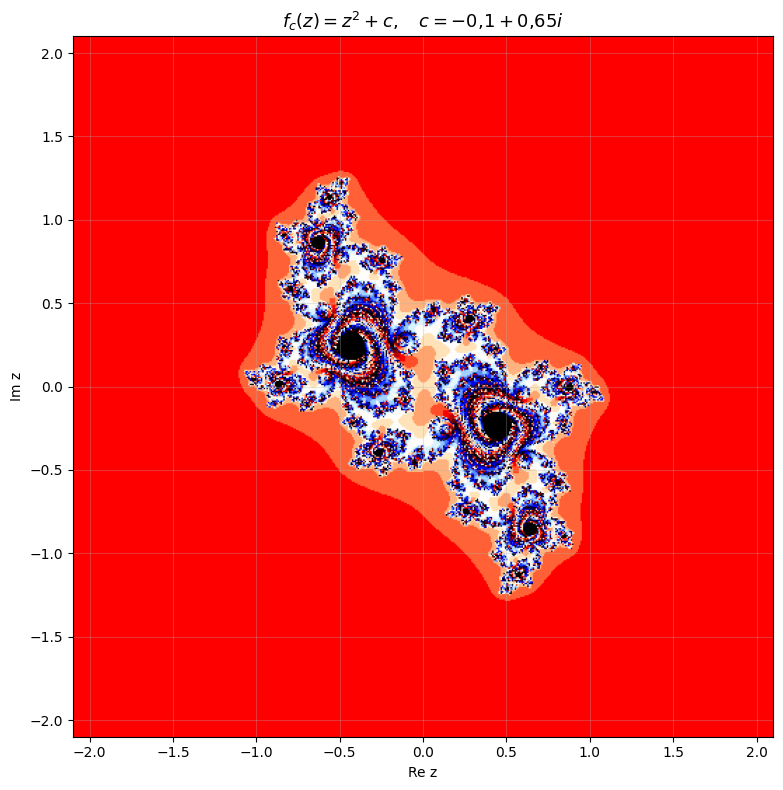

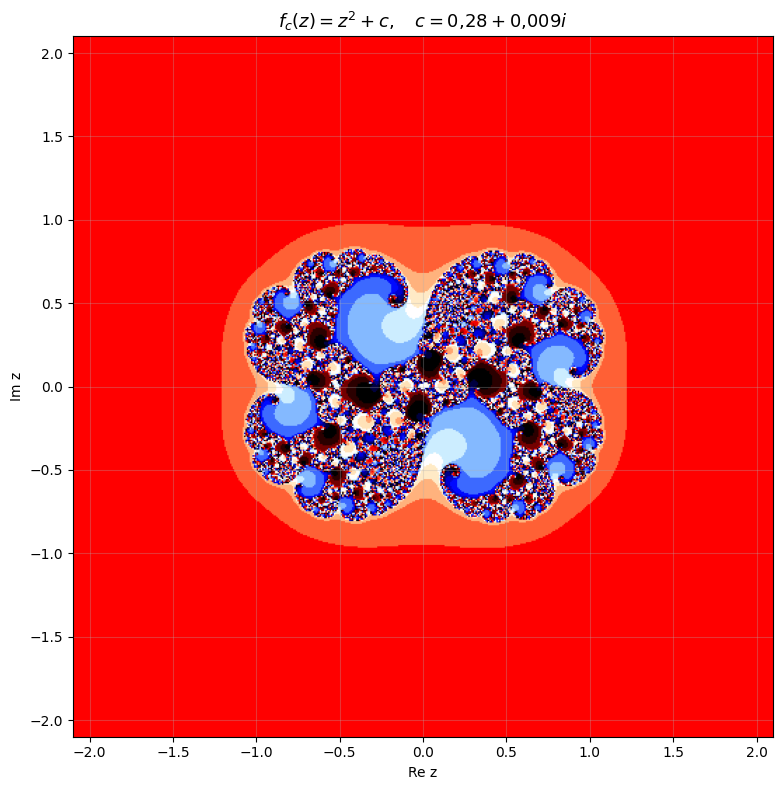

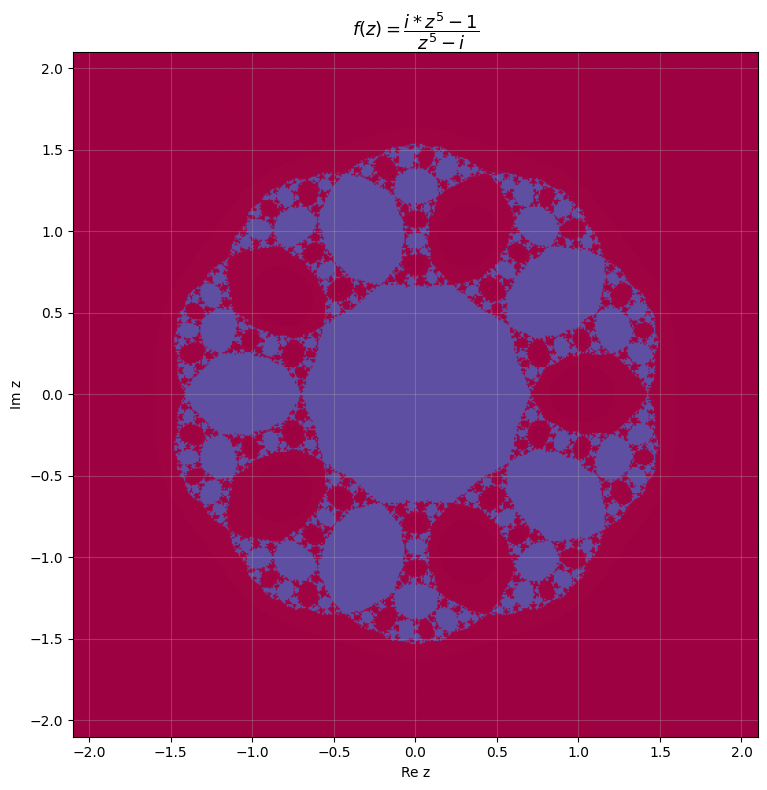

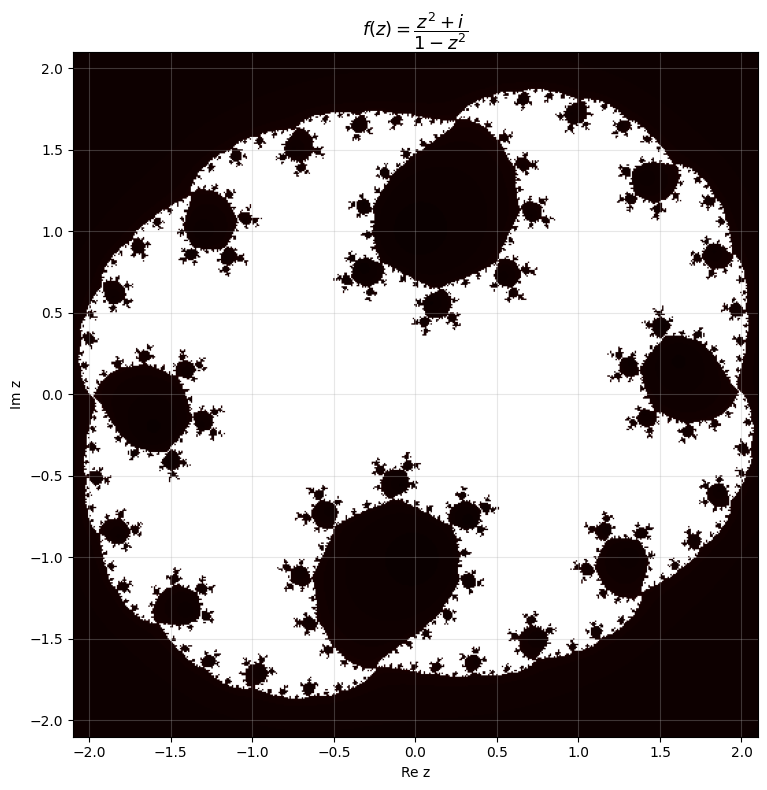

In [16]:
# ============================================================
# Задача 2.9. Строим четыре множества Жюлиа
# ============================================================

# --- 1) f_c(z) = z^2 + c,  c = -0.1 + 0.65i ---
c1 = complex(-0.1, 0.65)
f1 = lambda z, c=c1: z*z + c
J1 = draw_julia(f1,
                title=r"$f_c(z)=z^2+c,\quad c=-0{,}1+0{,}65i$",
                cmap='flag')

# --- 2) f_c(z) = z^2 + c,  c = 0.28 + 0.009i ---
c2 = complex(0.28, 0.009)
f2 = lambda z, c=c2: z*z + c
J2 = draw_julia(f2,
                title=r"$f_c(z)=z^2+c,\quad c=0{,}28+0{,}009i$",
                cmap='flag')

# --- 3) f(z) = (i - z^5) / (5 - i) ---
f3 = lambda z: (1j*z**5 - 1) / (z**5 - 1j)
J3 = draw_julia(f3,
                title=r"$f(z)=\dfrac{i*z^5-1}{z^5-i}$",
                cmap='Spectral')

# --- 4) f(z) = (z^2 + i z) / (1 - z^2) ---
f4 = lambda z: (z*z + 1j) / (1 - z**2)
J4 = draw_julia(f4,
                title=r"$f(z)=\dfrac{z^2+i}{1-z^2}$",
                cmap='hot')

## Что мы видим и почему

### Картинка 1: $c = -0{,}1 + 0{,}65i$ («кролик»)
Это классический пример связного множества Жюлиа. Точка $c$
принадлежит множеству Мандельброта (см. следующий пункт), поэтому
$J_c$ — **связное** множество (теорема Фату–Жюлиа: $J_c$ связно
$\iff$ орбита 0 ограничена). Форма напоминает кролика — характерный
пример «douady rabbit».

### Картинка 2: $c = 0{,}28 + 0{,}009i$ («дендрит»)
Точка $c$ лежит на границе множества Мандельброта, поэтому $J_c$ —
«дерево» без внутренности (топологически дендрит). Орбита 0
ограничена, но не притягивается ни к какому циклу — динамика на
границе хаотична.

### Картинка 3: $f(z) = \dfrac{i - z^5}{5-i}$
Это **рациональная** функция степени 5 (числитель $z^5$, знаменатель
константа). Её множество Жюлиа имеет симметрию 5-го порядка: если
$z \in J_f$, то $\omega z \in J_f$ для любого корня 5-й степени
из 1, $\omega = e^{2\pi i k/5}$. Это следует из того, что
$f(\omega z) = \omega^5 \cdot (\text{что-то}) = \omega^5 f(z)$ (при
подходящей нормировке).

### Картинка 4: $f(z) = \dfrac{z^2 + iz}{1 - z^2}$
Рациональная функция степени 2. Полюса в точках $z = \pm 1$. Множество
Жюлиа — множество точек, орбиты которых не сходятся ни к 0, ни к
полюсам. Симметрия связана с преобразованием $z \mapsto -z$:
$f(-z) = \dfrac{z^2 - iz}{1 - z^2}$, что не совпадает с $f(z)$, но
симметрия $z \mapsto \overline{z}$ (комплексное сопряжение) имеет
место, если коэффициенты вещественные или чисто мнимые.

## Связь с Лекцией 3 (прикладные диффуры)

Динамическая система $z \mapsto z^2 + c$ — это **дискретная**
динамическая система (время $n$ — целое). В бильярде из Лекции 3
система тоже дискретна (удары о стенки), и там тоже есть два режима:
- **рациональный** — периодические траектории;
- **иррациональный** — всюду плотные траектории.

Аналогично в множестве Жюлиа: точки внутри «лепестков» имеют
периодические (или притягивающиеся к периодическим) орбиты, а
точки на границе — хаотические. Это **универсальное** свойство
динамических систем: простое правило + итерация = сложное поведение.

## Инструменты реализации

| Библиотека | Зачем |
|---|---|
| `numpy` | сетка, массивы, быстрое вычисление |
| `matplotlib` | `imshow`, `cmap` — визуализация матрицы |
| `cmath` | комплексная арифметика |

**Производительность.** Двойной цикл `for ix, for iy` работает медленно
(500×500 = 250 000 итераций внешнего цикла, каждая ещё до 1000
внутренних). Если хочется быстрее — можно векторизовать через
`numpy` (сразу считать массив $Z$ комплексных чисел и обновлять
маской $|Z| \le R$). Но для учебных целей текущий код достаточно
нагляден.

# Задача 2.10. Сфера Римана и кривые на ней

## 1. Зачем нужна сфера Римана

Комплексная плоскость $\mathbb{C}$ не компактна: у неё «нет точки
на бесконечности». Чтобы исправить это, добавляют одну формальную
точку $\infty$ и получают **расширенную комплексную плоскость**
$$\overline{\mathbb{C}} = \mathbb{C} \cup \{\infty\}.$$

Сфера Римана — это **геометрическая модель** $\overline{\mathbb{C}}$:
обычная сфера, касающаяся плоскости в точке $O = (0,0,0)$,
с отождествлением «северного полюса» $N$ с точкой $\infty$.

**Почему это работает?** Стереографическая проекция из $N$ даёт
взаимно-однозначное соответствие между $\mathbb{C}$ и сферой без $N$.
При этом:
- окружности и прямые на $\mathbb{C}$ переходят в **окружности
  на сфере** (теорема: стереографическая проекция сохраняет углы и
  переводит обобщённые окружности в окружности);
- «бесконечно удалённая точка» становится обычной точкой $N$.

Это позволяет **компактифицировать** $\mathbb{C}$: например,
рациональные функции становятся отображениями сферы в себя, и
их динамика (множества Жюлиа из задачи 2.9) изучается именно на
сфере Римана.

## 2. Уравнение сферы и стереографическая проекция

Возьмём сферу радиуса $1/2$ с центром в $(0, 0, 1/2)$:
$$\xi^2 + \eta^2 + \left(\zeta - \tfrac{1}{2}\right)^2 = \tfrac{1}{4}.$$
Она касается плоскости $\zeta = 0$ в точке $O = (0,0,0)$,
а её северный полюс $N = (0, 0, 1)$.

**Проекция точки $z = x + iy$ на сферу.** Проведём луч из $N$
через точку $(x, y, 0)$ на плоскости. Он пересечёт сферу в точке
$Z = (\xi, \eta, \zeta)$. Параметризуем луч:
$$\xi = t x,\quad \eta = t y,\quad \zeta = 1 - t,\quad t \in [0,1].$$
Подставляя в уравнение сферы, находим $t = \dfrac{1}{1 + |z|^2}$.

**Прямая формула (из Лекции 2, стр. 33):**
$$\xi = \frac{x}{1 + |z|^2},\qquad
\eta = \frac{y}{1 + |z|^2},\qquad
\zeta = \frac{|z|^2}{1 + |z|^2}.$$

**Обратная формула:**
$$x = \frac{\xi}{1 - \zeta},\qquad
y = \frac{\eta}{1 - \zeta}.$$

При $z \to \infty$ получаем $\zeta \to 1$, то есть $N = (0,0,1)$.

## 3. Что нужно построить

Из листка 2.10:
- **а)** прямую на сфере;
- **б)** окружность на сфере;
- **в)** параболу;
- **г)** гиперболу;
- **д)** логарифмическую спираль $r = a e^{b\varphi}$.

**Ключевая идея:** берём параметризацию кривой на $\mathbb{C}$,
переводим её точки в сферу Римана по формуле $(\xi, \eta, \zeta)$,
и рисуем 3D-линию.

**Что мы увидим (теорема):**
- **Прямая** на $\mathbb{C}$, не проходящая через $\infty$, переходит
  в окружность на сфере, проходящую через $N$ (потому что прямая
  «уходит на бесконечность» обоими концами, а $\infty \to N$).
- **Окружность** на $\mathbb{C}$ переходит в окружность на сфере,
  **не** проходящую через $N$.
- **Парабола/гипербола** — тоже окружности на сфере, проходящие через
  $N$ (у них тоже есть ветви, уходящие на бесконечность).
- **Логарифмическая спираль** наматывается на сферу, подходя к $N$
  спиралью (если $b > 0$).

## 4. Инструменты реализации

- **NumPy** — параметризация кривых, массивы точек.
- **Matplotlib (`mpl_toolkits.mplot3d`)** — 3D-графики.
  - `Axes3D.plot` — линия на сфере;
  - `Axes3D.plot_surface` — сама сфера (полупрозрачная);
  - `Axes3D.set_box_aspect` — чтобы сфера не была сплюснутой.

**План:**
1. Функция `to_sphere(x, y)` — переводит точки плоскости на сферу.
2. Функция `draw_sphere(ax)` — рисует полупрозрачную сферу-каркас.
3. Для каждой кривой: параметризация → перевод → `ax.plot`.
4. Выводим 5 картинок (или 1 общий рисунок с 5 панелями).

In [6]:
# ============================================================
# Задача 2.10. Функции для сферы Римана
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D   # 3D-графика

def to_sphere(x, y):
    """
    Стереографическая проекция точки (x, y) плоскости C
    на сферу Римана радиуса 1/2 с центром (0, 0, 1/2).
    
    Формулы (Лекция 2, стр. 33):
      xi  = x / (1 + |z|^2)
      eta = y / (1 + |z|^2)
      zeta = |z|^2 / (1 + |z|^2)
    """
    r2 = x*x + y*y                    # |z|^2
    denom = 1.0 + r2
    xi  = x / denom
    eta = y / denom
    zeta = r2 / denom
    return xi, eta, zeta

def draw_sphere(ax, color='lightsteelblue', alpha=0.25):
    """
    Рисует полупрозрачную сферу радиуса 1/2 с центром (0, 0, 1/2)
    через параметризацию (phi, theta).
    """
    phi   = np.linspace(0, 2*np.pi, 60)
    theta = np.linspace(0, np.pi, 30)
    Phi, Theta = np.meshgrid(phi, theta)
    # параметризация сферы радиуса R=0.5 с центром (0,0,0.5)
    R = 0.5
    X = R * np.sin(Theta) * np.cos(Phi)
    Y = R * np.sin(Theta) * np.sin(Phi)
    Z = 0.5 + R * np.cos(Theta)
    ax.plot_surface(X, Y, Z, color=color, alpha=alpha,
                    rstride=2, cstride=2, linewidth=0,
                    edgecolor='gray')

def setup_3d_axes(ax, title=""):
    """Настройка осей для красивой визуализации сферы Римана."""
    ax.set_xlabel(r"$\xi$")
    ax.set_ylabel(r"$\eta$")
    ax.set_zlabel(r"$\zeta$")
    ax.set_title(title, fontsize=12)
    ax.set_box_aspect([1, 1, 1])          # кубическая область
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.6, 0.6)
    ax.set_zlim(-0.05, 1.05)
    # отметим северный полюс N = (0,0,1) и южный O = (0,0,0)
    ax.scatter([0], [0], [1], color='red', s=30, zorder=5)
    ax.scatter([0], [0], [0], color='green', s=30, zorder=5)
    ax.text(0, 0, 1.08, r"$N=\infty$", color='red', fontsize=11)
    ax.text(0, 0, -0.08, r"$O$", color='green', fontsize=11)

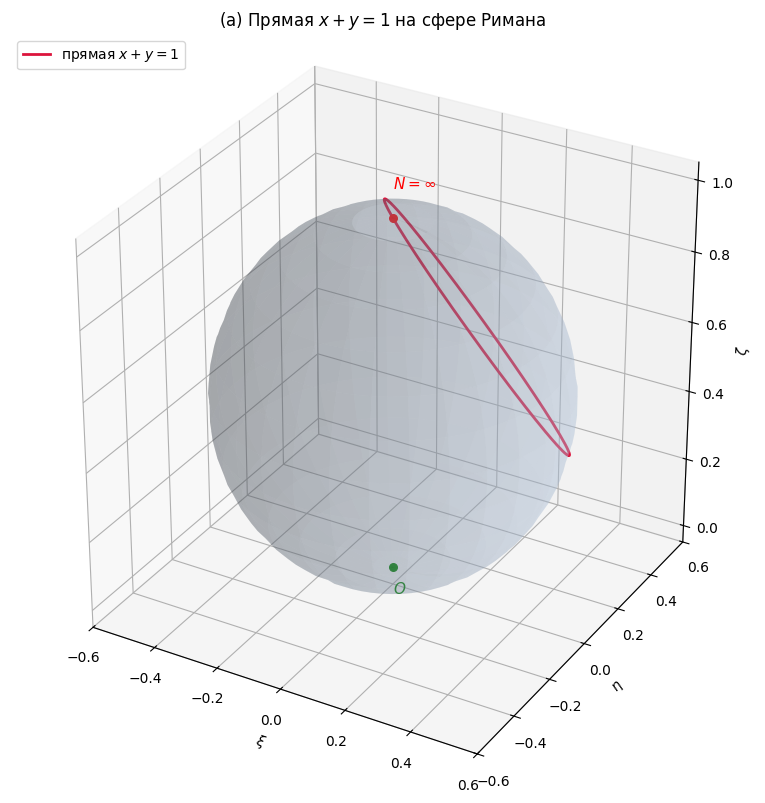

In [7]:
# ============================================================
# Задача 2.10а. Прямая на сфере Римана
# ============================================================
# Возьмём прямую x + y = 1 (не проходит через начало координат).
# Параметризуем: x = t, y = 1 - t, t in R.
t = np.linspace(-50, 50, 3000)   # большой диапазон, чтобы дойти до N
x_line = t
y_line = 1 - t

xi, eta, zeta = to_sphere(x_line, y_line)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
draw_sphere(ax)
ax.plot(xi, eta, zeta, color='crimson', linewidth=2,
        label=r"прямая $x+y=1$")
setup_3d_axes(ax, r"(а) Прямая $x+y=1$ на сфере Римана")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

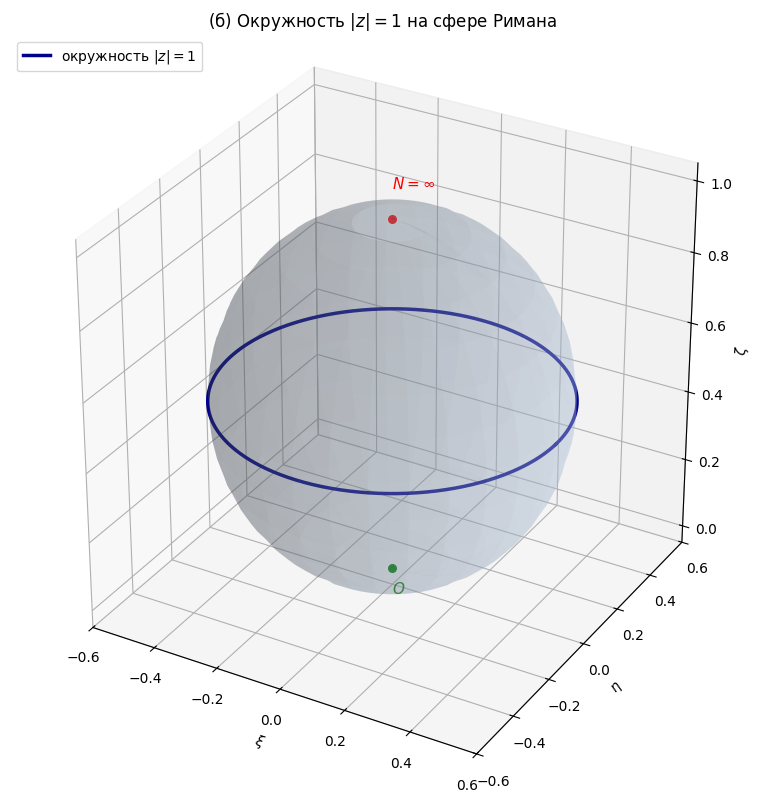

In [8]:
# ============================================================
# Задача 2.10б. Окружность на сфере Римана
# ============================================================
# Возьмём окружность |z| = 1: x = cos(t), y = sin(t), t in [0, 2pi].
t = np.linspace(0, 2*np.pi, 500)
x_circ = np.cos(t)
y_circ = np.sin(t)

xi, eta, zeta = to_sphere(x_circ, y_circ)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
draw_sphere(ax)
ax.plot(xi, eta, zeta, color='darkblue', linewidth=2.5,
        label=r"окружность $|z|=1$")
setup_3d_axes(ax, r"(б) Окружность $|z|=1$ на сфере Римана")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

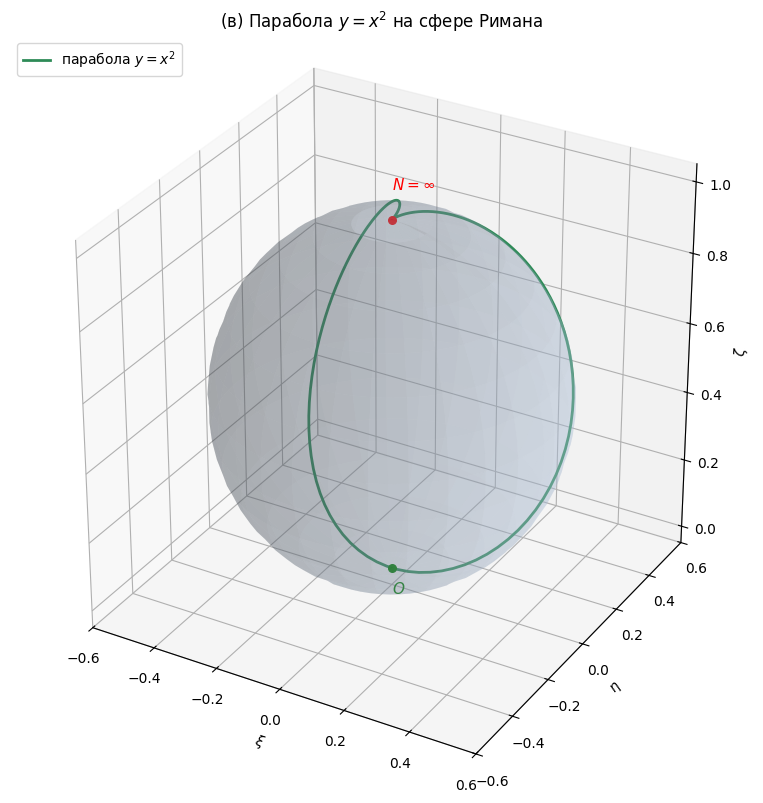

In [9]:
# ============================================================
# Задача 2.10в. Парабола на сфере Римана
# ============================================================
# Возьмём параболу y = x^2: параметризация x = t, y = t^2.
t = np.linspace(-50, 50, 3000)
x_par = t
y_par = t**2

xi, eta, zeta = to_sphere(x_par, y_par)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
draw_sphere(ax)
ax.plot(xi, eta, zeta, color='seagreen', linewidth=2,
        label=r"парабола $y=x^2$")
setup_3d_axes(ax, r"(в) Парабола $y=x^2$ на сфере Римана")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

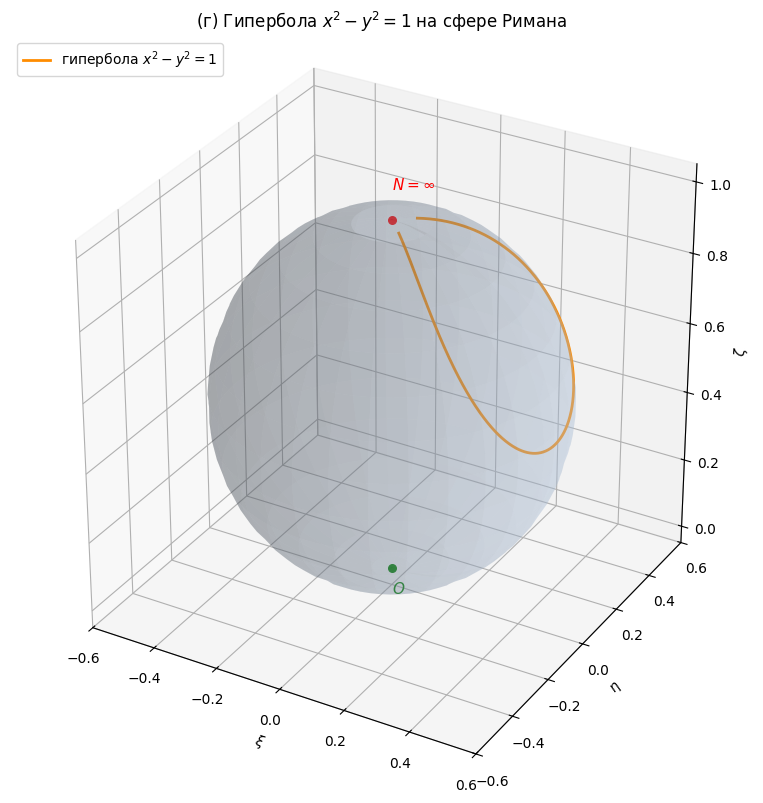

In [10]:
# ============================================================
# Задача 2.10г. Гипербола на сфере Римана
# ============================================================
# Возьмём гиперболу x^2 - y^2 = 1.
# Параметризация: x = cosh(t), y = sinh(t), t in R.
t = np.linspace(-3, 3, 1000)
x_hyp = np.cosh(t)
y_hyp = np.sinh(t)

xi, eta, zeta = to_sphere(x_hyp, y_hyp)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
draw_sphere(ax)
ax.plot(xi, eta, zeta, color='darkorange', linewidth=2,
        label=r"гипербола $x^2-y^2=1$")
setup_3d_axes(ax, r"(г) Гипербола $x^2-y^2=1$ на сфере Римана")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

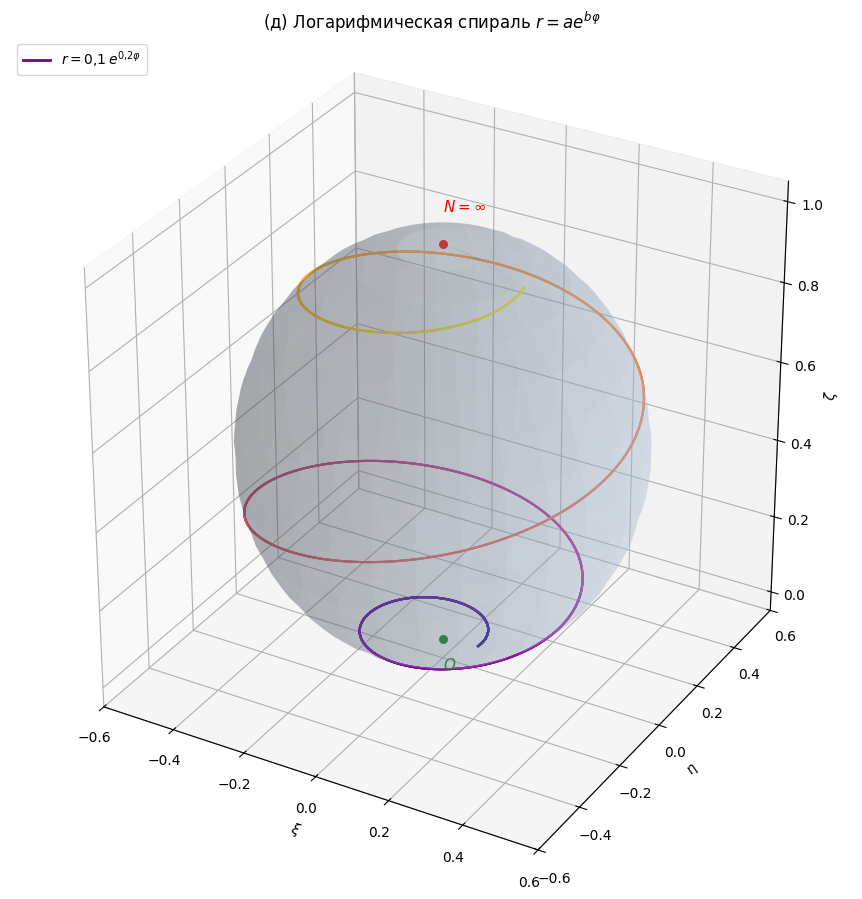

In [11]:
# ============================================================
# Задача 2.10д. Логарифмическая спираль на сфере Римана
# ============================================================
# r = a * exp(b * phi), в декартовых: x = r cos(phi), y = r sin(phi).
a, b = 0.1, 0.2
phi = np.linspace(0, 6*np.pi, 4000)     # 3 полных оборота
r = a * np.exp(b * phi)
x_sp = r * np.cos(phi)
y_sp = r * np.sin(phi)

xi, eta, zeta = to_sphere(x_sp, y_sp)

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection='3d')
draw_sphere(ax)
# Рисуем линию с цветовой градацией по параметру phi
from matplotlib import cm
N = len(phi)
colors = cm.plasma(np.linspace(0, 1, N))
# plot с массивом цветов может тормозить; разобьём на сегменты
for i in range(0, N-1, 1):
    ax.plot(xi[i:i+2], eta[i:i+2], zeta[i:i+2],
            color=colors[i], linewidth=1.5)
setup_3d_axes(ax, r"(д) Логарифмическая спираль $r=ae^{b\varphi}$")
# Легенда вручную
ax.plot([], [], [], color='purple', linewidth=2,
        label=r"$r = 0{,}1\,e^{0{,}2\varphi}$")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

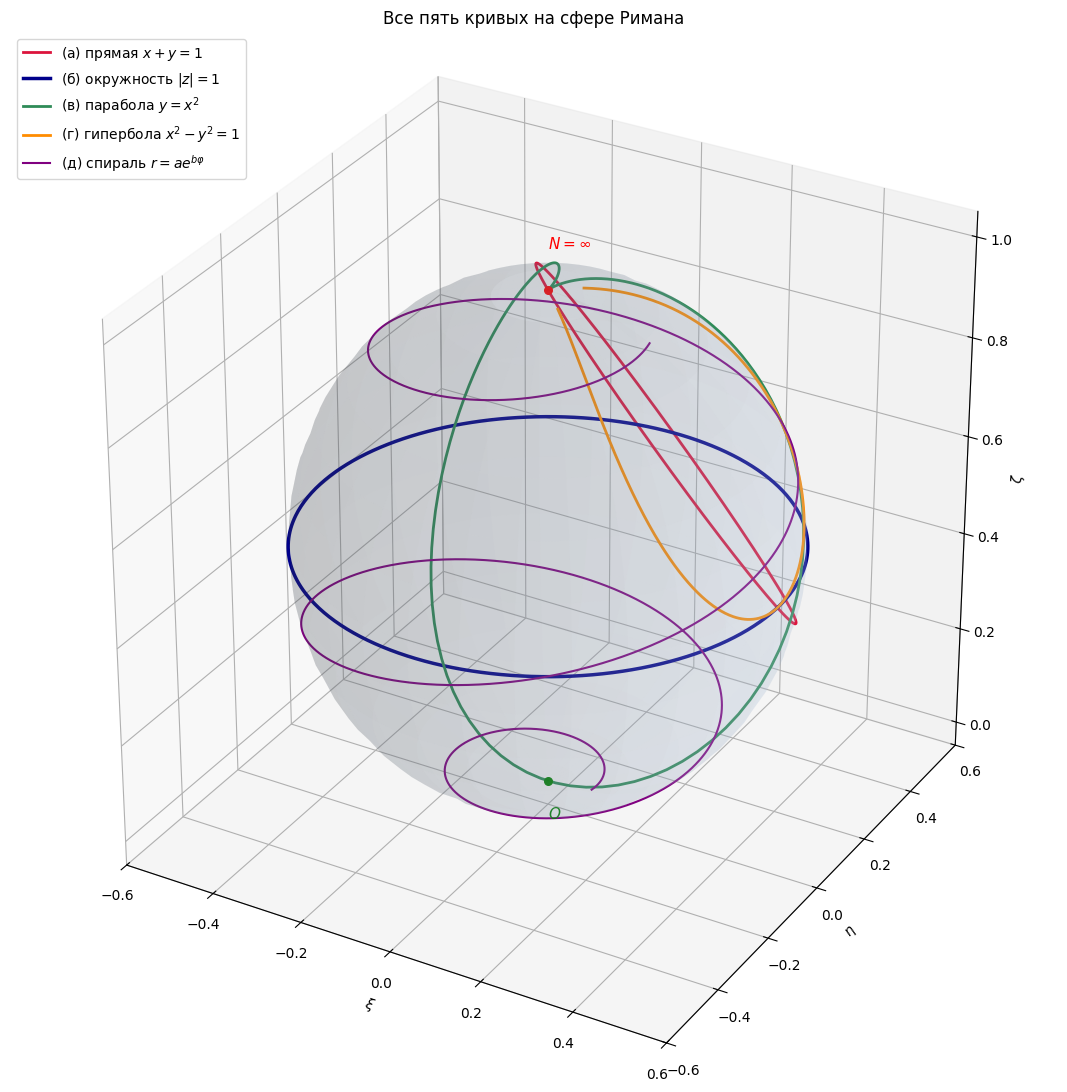

In [12]:
# ============================================================
# Задача 2.10. Все пять кривых на одной сфере
# ============================================================
fig = plt.figure(figsize=(11, 11))
ax = fig.add_subplot(111, projection='3d')
draw_sphere(ax, alpha=0.15)

# --- (а) прямая x+y=1 ---
t1 = np.linspace(-50, 50, 3000)
xi, eta, zeta = to_sphere(t1, 1 - t1)
ax.plot(xi, eta, zeta, color='crimson', lw=2,
        label=r"(а) прямая $x+y=1$")

# --- (б) окружность |z|=1 ---
t2 = np.linspace(0, 2*np.pi, 500)
xi, eta, zeta = to_sphere(np.cos(t2), np.sin(t2))
ax.plot(xi, eta, zeta, color='darkblue', lw=2.5,
        label=r"(б) окружность $|z|=1$")

# --- (в) парабола y=x^2 ---
t3 = np.linspace(-50, 50, 3000)
xi, eta, zeta = to_sphere(t3, t3**2)
ax.plot(xi, eta, zeta, color='seagreen', lw=2,
        label=r"(в) парабола $y=x^2$")

# --- (г) гипербола x^2 - y^2 = 1 ---
t4 = np.linspace(-3, 3, 1000)
xi, eta, zeta = to_sphere(np.cosh(t4), np.sinh(t4))
ax.plot(xi, eta, zeta, color='darkorange', lw=2,
        label=r"(г) гипербола $x^2-y^2=1$")

# --- (д) логарифмическая спираль ---
a, b = 0.1, 0.2
phi = np.linspace(0, 6*np.pi, 4000)
r = a * np.exp(b * phi)
xi, eta, zeta = to_sphere(r*np.cos(phi), r*np.sin(phi))
ax.plot(xi, eta, zeta, color='purple', lw=1.5,
        label=r"(д) спираль $r=ae^{b\varphi}$")

setup_3d_axes(ax, "Все пять кривых на сфере Римана")
ax.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()